<a href="https://colab.research.google.com/github/gustavokbb/TCC-CApA-2026-Deteccao-e-Classificacao/blob/main/02_Classificacao_Drones_DenseNet201_ALT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TCC — Classificação de drones com DenseNet201

## 1. Objetivo do experimento

Classificar imagens de drones nas categorias **DJI Inspire, DJI Mavic, DJI Phantom e ausência de drone**, utilizando uma DenseNet201 inicialmente pré-treinada no ImageNet e adaptada ao conjunto sintético Cranfield.

O experimento avalia a classificação em imagens sintéticas e em recortes de 12 sequências reais do Anti-UAV. Nos vídeos, a localização dos drones é fornecida pelas anotações do dataset. Este notebook realiza a classificação; a detecção e sua integração com o classificador são tratadas separadamente.

### Índice do notebook

| Seção | Conteúdo |
|---|---|
| 1 | Objetivo e escopo do experimento |
| 2 | Como utilizar o notebook |
| 3 | Configuração do ambiente e conferência do dataset |
| 4 | Pré-processamento de cada etapa |
| 5 | Arquitetura DenseNet201 e preparação para novo treinamento |
| 6 | Treinamento incremental e históricos de 10, 20 e 50 épocas |
| 7 | Resultados da validação sintética |
| 8 | Reprodução da avaliação real no Anti-UAV |
| 9 | Resultados reais com o pré-processamento proporcional |
| 10 | Comparação dos pré-processamentos e inspeções opcionais |
| 11 | Teste com fotografia própria e comparação opcional |
| 12 | Conclusões preliminares |

Use também o **Índice** na barra lateral do Colab para acessar cada seção.

## 2. Como utilizar

1. Entre em uma conta Google para executar os códigos. Se desejar guardar uma versão própria com suas alterações e resultados, utilize **Arquivo → Salvar uma cópia no Drive**. A cópia é opcional; visitantes com permissão de leitura não podem modificar a versão original.
2. Execute as **duas células de configuração da seção 3**, na ordem, pelo botão ▶ à esquerda, e aguarde a conclusão. Os datasets, o checkpoint e os resultados são baixados por links públicos, sem solicitar acesso ao seu Drive.
3. Para **consultar os resultados**, execute somente as células de apresentação em **6.1.1, 6.2.1 e 6.3.1**, **7.1 a 7.3** e **9.1 a 9.3**. Para consultar a comparação dos pré-processamentos, execute a primeira célula da **seção 10**. Não é necessário treinar a rede nem processar novamente os vídeos.
4. Para **testar uma fotografia própria**, siga para **11.1** após a configuração inicial. Troque `EXECUTAR_TESTE_EXTERNO = False` por `True`, execute a célula e envie uma imagem JPG, PNG ou WebP recortada ao redor de um único drone, sem caixas ou textos desenhados. A opção **11.2** compara os dois pré-processamentos na mesma fotografia; execute-a somente se desejar essa análise.
5. Para **repetir a avaliação real**, execute as células da **seção 8**, na ordem, e a célula de salvamento no início da **seção 9**. Baixe o ZIP oferecido por essa célula antes de encerrar a sessão. Cada execução fica em uma pasta própria no Colab, separada dos resultados publicados; os arquivos temporários podem ser apagados ao encerrar o ambiente.
6. Para **treinar novamente**, leia a seção 5 e prepare os caminhos de salvamento para sua execução antes de seguir para a seção 6. As células originais de treinamento usam caminhos no Drive e não são necessárias para a consulta nem para os testes externos.

**Não utilize “Executar tudo” para uma consulta ou teste rápido**, pois essa opção também executa as células de treinamento.

**Diferença entre as etapas:** o treinamento e a validação sintética mantêm o processamento original. A avaliação real e o teste externo adotam o redimensionamento proporcional com bordas. A mudança foi avaliada com o mesmo checkpoint, sem novo treinamento. Os procedimentos estão descritos na seção 4 e comparados na seção 10.

## 3. Configuração do ambiente

Execute as duas células abaixo uma vez após cada reinício do Colab. A primeira baixa e verifica os arquivos públicos, recria os conjuntos de dados e carrega o melhor checkpoint e os resultados publicados. A segunda prepara a função de consulta dos históricos da seção 6. Essas células **não realizam treinamento**.

Serão recuperadas **4.001 imagens de treinamento**, **4.000 de validação** e **12 sequências reais**, além dos históricos e dos resultados dos dois pré-processamentos. Os arquivos da proposta inicial permanecem separados dos resultados proporcionais.

A configuração seleciona GPU quando disponível ou utiliza CPU. Após a conclusão, siga diretamente para a consulta ou o teste desejado, conforme as orientações acima.


In [ ]:
# ============================================================
# CONFIGURAÇÃO E RESTAURAÇÃO COMPLETA DO AMBIENTE
#
# Este bloco:
# 1. Baixa publicamente os datasets;
# 2. Baixa os resultados e checkpoints já obtidos;
# 3. Extrai e verifica os arquivos;
# 4. Recria datasets e DataLoaders;
# 5. Carrega a DenseNet201 treinada;
# 6. Carrega os históricos dos experimentos;
# 7. Apresenta automaticamente os principais resultados.
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES
# ============================================================

from pathlib import Path

import os
import sys
import zipfile
import random
import subprocess
import json

import numpy as np
import pandas as pd

import torch
import torchvision
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torchvision.models import densenet201
from torch.utils.data import DataLoader

from IPython.display import display, Image as IPImage


# ============================================================
# 2. GDOWN
# ============================================================

# gdown permite baixar arquivos públicos do Google Drive
# utilizando somente o ID do arquivo.

try:
    import gdown

except ImportError:

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "gdown"
    ])

    import gdown


# ============================================================
# 3. IDs PÚBLICOS DO GOOGLE DRIVE
# ============================================================

# ------------------------------------------------------------
# Dataset sintético Cranfield
# ------------------------------------------------------------

ID_CRANFIELD = (
    "1F58wEvngww0G43UPCr3BtJV4bmPVPJRV"
)


# ------------------------------------------------------------
# Anti-UAV — 12 sequências RGB utilizadas no teste real
# ------------------------------------------------------------

ID_ANTI_UAV = (
    "10QHOLL5oaUtVm8eiy_rSYxN7rbw52iPF"
)


# ------------------------------------------------------------
# Resultados + checkpoints dos experimentos já realizados
# ------------------------------------------------------------

ID_RESULTADOS = (
    "1Rw1Y1Jm9cifJ0DcWhQWoY5-fDCJWdQSi"
)


# ============================================================
# 4. CAMINHOS LOCAIS DO COLAB
# ============================================================

ZIP_CRANFIELD = Path(
    "/content/cranfield-synthetic-drone-classification.zip"
)

ZIP_ANTI_UAV = Path(
    "/content/anti-uav-artigo24-12-sequencias.zip"
)

ZIP_RESULTADOS = Path(
    "/content/resultados-checkpoints-classificacao.zip"
)


PASTA_DATASET = Path(
    "/content/cranfield_dataset"
)

ANTI_UAV_DIR = Path(
    "/content/anti_uav_real"
)

ARTEFATOS_DIR = Path(
    "/content/artefatos_classificacao"
)


# ============================================================
# 5. DOWNLOAD PÚBLICO
# ============================================================

def baixar_google_drive(
    file_id,
    destino,
    descricao
):
    """
    Baixa um arquivo público do Google Drive.

    Se o arquivo já estiver disponível localmente
    e for um ZIP válido, o download não é repetido.
    """

    if (
        destino.is_file()
        and zipfile.is_zipfile(destino)
    ):

        print(
            f"✓ {descricao}: já disponível."
        )

        return


    print("\n" + "-" * 70)
    print(f"Baixando: {descricao}")
    print("-" * 70)


    resultado = gdown.download(
        id=file_id,
        output=str(destino),
        quiet=False
    )


    if resultado is None:

        raise RuntimeError(
            f"Falha no download de: {descricao}"
        )


    if not destino.is_file():

        raise FileNotFoundError(
            f"Arquivo não encontrado após download: "
            f"{destino}"
        )


    if not zipfile.is_zipfile(destino):

        raise zipfile.BadZipFile(
            f"Arquivo inválido: {destino}"
        )


    print(
        f"✓ Download concluído: {descricao}"
    )

    print(
        f"  Tamanho: "
        f"{destino.stat().st_size:,} bytes"
    )


# ============================================================
# 6. BAIXAR OS TRÊS PACOTES
# ============================================================

baixar_google_drive(
    ID_CRANFIELD,
    ZIP_CRANFIELD,
    "Cranfield Synthetic Drone Classification Dataset"
)

baixar_google_drive(
    ID_ANTI_UAV,
    ZIP_ANTI_UAV,
    "Anti-UAV — 12 sequências RGB"
)

baixar_google_drive(
    ID_RESULTADOS,
    ZIP_RESULTADOS,
    "Resultados e checkpoints da classificação"
)


# ============================================================
# 7. EXTRAÇÃO SEGURA
# ============================================================

def extrair_zip(
    arquivo_zip,
    destino
):
    """
    Extrai o conteúdo do ZIP e verifica se todos
    os arquivos permanecem dentro da pasta destino.
    """

    if not arquivo_zip.is_file():

        raise FileNotFoundError(
            f"ZIP ausente: {arquivo_zip}"
        )


    if not zipfile.is_zipfile(
        arquivo_zip
    ):

        raise zipfile.BadZipFile(
            f"ZIP inválido: {arquivo_zip}"
        )


    destino.mkdir(
        parents=True,
        exist_ok=True
    )


    print(
        f"\nExtraindo: {arquivo_zip.name}"
    )


    with zipfile.ZipFile(
        arquivo_zip,
        "r"
    ) as arquivo:

        raiz = destino.resolve()


        for item in arquivo.infolist():

            caminho = (
                destino /
                item.filename
            ).resolve()


            if not caminho.is_relative_to(
                raiz
            ):

                raise ValueError(
                    "Caminho inválido dentro do ZIP: "
                    f"{item.filename}"
                )


        arquivo.extractall(
            destino
        )


    print(
        f"✓ Extraído em: {destino}"
    )


# ============================================================
# 8. EXTRAIR OS TRÊS PACOTES
# ============================================================

extrair_zip(
    ZIP_CRANFIELD,
    PASTA_DATASET
)

extrair_zip(
    ZIP_ANTI_UAV,
    ANTI_UAV_DIR
)

extrair_zip(
    ZIP_RESULTADOS,
    ARTEFATOS_DIR
)


# ============================================================
# 9. LOCALIZAR AUTOMATICAMENTE AS PASTAS EXTRAÍDAS
# ============================================================

def localizar_pasta(
    raiz,
    caminho_relativo
):
    """
    Localiza uma pasta mesmo que o ZIP possua
    uma pasta adicional envolvendo o conteúdo.
    """

    relativo = Path(
        caminho_relativo
    )

    direto = raiz / relativo


    if direto.is_dir():

        return direto


    partes = relativo.parts


    for pasta in raiz.rglob(
        relativo.name
    ):

        if not pasta.is_dir():

            continue


        if tuple(
            pasta.parts[-len(partes):]
        ) == partes:

            return pasta


    raise FileNotFoundError(
        f"Pasta não localizada: {caminho_relativo}"
    )


# ============================================================
# 10. CAMINHOS DO CRANFIELD
# ============================================================

BASE = localizar_pasta(
    PASTA_DATASET,
    "cranfield-synthetic-drone-classification"
)

TRAIN = TRAIN_DIR = (
    BASE /
    "train"
)

VAL = VAL_DIR = (
    BASE /
    "val"
)


# ============================================================
# 11. CAMINHOS DO ANTI-UAV
# ============================================================

RAIZ_REAL = localizar_pasta(
    ANTI_UAV_DIR,
    "artigo24-12-sequencias"
)

MAVIC_SINTETICO = (
    TRAIN_DIR /
    "dji_mavic"
)

MAVIC_REAL = (
    RAIZ_REAL /
    "dji_mavic"
)


# ============================================================
# 12. CAMINHOS DOS RESULTADOS E CHECKPOINTS
# ============================================================

PASTA_RESULTADOS = localizar_pasta(
    ARTEFATOS_DIR,
    "resultados/densenet201_incremental"
)

PASTA_CHECKPOINTS = localizar_pasta(
    ARTEFATOS_DIR,
    "checkpoints/densenet201_incremental"
)

PASTA_RESULTADOS_REAL = localizar_pasta(
    ARTEFATOS_DIR,
    "resultados/anti_uav_real"
)


# ============================================================
# 13. VERIFICAÇÃO DO DATASET SINTÉTICO
# ============================================================

CLASSES_ESPERADAS = [
    "dji_inspire",
    "dji_mavic",
    "dji_phantom",
    "no_drone"
]


for divisao in (
    TRAIN_DIR,
    VAL_DIR
):

    for classe in (
        CLASSES_ESPERADAS
    ):

        pasta = (
            divisao /
            classe
        )


        if not pasta.is_dir():

            raise FileNotFoundError(
                f"Pasta ausente: {pasta}"
            )


# ============================================================
# 14. VERIFICAÇÃO DO DATASET REAL
# ============================================================

sequencias_verificadas = []


for classe in (
    CLASSES_ESPERADAS[:3]
):

    pasta = (
        RAIZ_REAL /
        classe
    )


    if not pasta.is_dir():

        raise FileNotFoundError(
            f"Pasta real ausente: {pasta}"
        )


    sequencias = sorted(
        p
        for p in pasta.iterdir()
        if p.is_dir()
    )


    if len(sequencias) != 4:

        raise ValueError(
            f"{classe}: esperadas 4 sequências, "
            f"encontradas {len(sequencias)}."
        )


    for sequencia in sequencias:

        for nome in (
            "visible.mp4",
            "visible.json"
        ):

            arquivo = (
                sequencia /
                nome
            )


            if (
                not arquivo.is_file()
                or arquivo.stat().st_size == 0
            ):

                raise FileNotFoundError(
                    f"Arquivo real ausente: "
                    f"{arquivo}"
                )


    sequencias_verificadas.extend(
        sequencias
    )


# ============================================================
# 15. REPRODUTIBILIDADE
# ============================================================

SEED = 0


random.seed(
    SEED
)

np.random.seed(
    SEED
)

torch.manual_seed(
    SEED
)


if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        SEED
    )


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# 16. GAUSSIAN NOISE
# ============================================================

class GaussianNoise:

    def __init__(
        self,
        mean=0.75,
        std=0.75,
        p=0.75
    ):

        self.mean = mean
        self.std = std
        self.p = p


    def __call__(
        self,
        tensor
    ):

        if (
            torch.rand(1).item()
            < self.p
        ):

            noise = (
                torch.randn_like(
                    tensor
                )
                * self.std
                + self.mean
            )

            return tensor + noise


        return tensor


# ============================================================
# 17. TRANSFORMAÇÕES
# ============================================================

imagenet_mean = [
    0.485,
    0.456,
    0.406
]

imagenet_std = [
    0.229,
    0.224,
    0.225
]


train_transform = transforms.Compose([

    transforms.Resize(
        (256, 256)
    ),

    transforms.RandomCrop(
        224
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    ),

    GaussianNoise(
        mean=0.75,
        std=0.75,
        p=0.75
    )

])


val_transform = transforms.Compose([

    transforms.Resize(
        (256, 256)
    ),

    transforms.CenterCrop(
        224
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )

])


# ============================================================
# 18. DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_transform
)


# ============================================================
# 19. DATALOADERS
# ============================================================

BATCH_SIZE = 32


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 20. VERIFICAÇÕES DO CRANFIELD
# ============================================================

if (
    train_dataset.classes
    != CLASSES_ESPERADAS
):

    raise ValueError(
        "Classes de treinamento incorretas."
    )


if (
    val_dataset.classes
    != CLASSES_ESPERADAS
):

    raise ValueError(
        "Classes de validação incorretas."
    )


if (
    train_dataset.class_to_idx
    != val_dataset.class_to_idx
):

    raise ValueError(
        "Mapeamentos de classes diferentes."
    )


if (
    len(train_dataset),
    len(val_dataset)
) != (
    4001,
    4000
):

    raise ValueError(
        f"Esperadas 4001/4000 imagens; "
        f"encontradas "
        f"{len(train_dataset)}/"
        f"{len(val_dataset)}."
    )


# ============================================================
# 21. CARREGAR O MELHOR MODELO JÁ TREINADO
# ============================================================

BEST_MODEL_PATH = (
    PASTA_CHECKPOINTS /
    "best_model_ate_50epocas.pt"
)


if not BEST_MODEL_PATH.is_file():

    raise FileNotFoundError(
        f"Melhor modelo não encontrado: "
        f"{BEST_MODEL_PATH}"
    )


model = densenet201(
    weights=None
)


num_features = (
    model.classifier.in_features
)


model.classifier = nn.Sequential(

    nn.Dropout(
        p=0.25
    ),

    nn.Linear(
        num_features,
        4
    )

)


model = model.to(
    device
)


checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)


model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


model.eval()


# ============================================================
# 22. RECRIAR FUNÇÃO DE PERDA E OTIMIZADOR
# ============================================================

criterion = nn.CrossEntropyLoss()


optimizer = optim.SGD(

    model.parameters(),

    lr=0.0001,

    momentum=0.9

)


# Se o checkpoint possuir o estado do otimizador,
# ele também é restaurado.

if (
    "optimizer_state_dict"
    in checkpoint
):

    optimizer.load_state_dict(
        checkpoint[
            "optimizer_state_dict"
        ]
    )


# ============================================================
# 23. CARREGAR HISTÓRICO DAS 50 ÉPOCAS
# ============================================================

HISTORY_50 = (
    PASTA_RESULTADOS /
    "historico_ate_50epocas.csv"
)


if not HISTORY_50.is_file():

    raise FileNotFoundError(
        f"Histórico não encontrado: "
        f"{HISTORY_50}"
    )


df_historico = pd.read_csv(
    HISTORY_50
)


# ============================================================
# 24. RESUMO DOS MARCOS 10 / 20 / 50
# ============================================================

resumo_etapas = []


for limite in (
    10,
    20,
    50
):

    parte = df_historico[
        df_historico[
            "epoch"
        ] <= limite
    ]


    melhor_indice = (
        parte[
            "val_accuracy"
        ].idxmax()
    )


    melhor = parte.loc[
        melhor_indice
    ]


    resumo_etapas.append({

        "Treinamento até": (
            f"{limite} épocas"
        ),

        "Melhor época": int(
            melhor["epoch"]
        ),

        "Melhor Val Accuracy (%)": round(
            melhor[
                "val_accuracy"
            ] * 100,
            2
        ),

        "Val Loss": round(
            melhor[
                "val_loss"
            ],
            4
        )

    })


df_resumo_etapas = pd.DataFrame(
    resumo_etapas
)


# ============================================================
# 25. CARREGAR MÉTRICAS SINTÉTICAS
# ============================================================

CAMINHO_METRICAS = (
    PASTA_RESULTADOS /
    "metricas_finais_validacao.json"
)


metricas_sinteticas = None


if CAMINHO_METRICAS.is_file():

    with open(
        CAMINHO_METRICAS,
        "r",
        encoding="utf-8"
    ) as f:

        metricas_sinteticas = (
            json.load(f)
        )


# ============================================================
# 26. CARREGAR RESULTADOS DO ANTI-UAV REAL
# ============================================================

CAMINHO_FRAMES_REAL = (
    PASTA_RESULTADOS_REAL /
    "resultados_por_frame.csv"
)

CAMINHO_VIDEOS_REAL = (
    PASTA_RESULTADOS_REAL /
    "resultados_por_video.csv"
)


df_frames_real = None
df_videos_real = None


if CAMINHO_FRAMES_REAL.is_file():

    df_frames_real = pd.read_csv(
        CAMINHO_FRAMES_REAL
    )


if CAMINHO_VIDEOS_REAL.is_file():

    df_videos_real = pd.read_csv(
        CAMINHO_VIDEOS_REAL
    )

print("\n" + "=" * 70)
print("AMBIENTE RESTAURADO COM SUCESSO")
print("=" * 70)

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available()
      else "CPU")

print("Imagens de treinamento:", len(train_dataset))
print("Imagens de validação:", len(val_dataset))
print("Sequências reais:", len(sequencias_verificadas))

print("\nArtefatos dos experimentos carregados.")
print("Melhor modelo:", BEST_MODEL_PATH.name)
print("Melhor época:", checkpoint["epoch"])
print(f"Val Accuracy: {checkpoint['val_accuracy'] * 100:.2f}%")

print("\nO notebook está pronto para exibir os resultados")
print("nas respectivas seções sem realizar novo treinamento.")

# ============================================================
# 27. RESULTADOS DA COMPARAÇÃO E PRÉ-PROCESSAMENTO REAL
# ============================================================
# O pacote original permanece intacto e disponível separadamente.
PASTA_RESULTADOS_REAL_ORIGINAL = PASTA_RESULTADOS_REAL
if df_frames_real is None or df_videos_real is None:
    raise FileNotFoundError("Os resultados reais originais não foram restaurados.")
df_frames_real_original = df_frames_real.copy()
df_videos_real_original = df_videos_real.copy()

ID_COMPARACAO = "1drUHKlb6mkSbz3k96lxOM9CfCmt_NqqP"
ZIP_COMPARACAO = Path("/content/resultados-comparacao-preprocessamento-anti-uav.zip")
PASTA_COMPARACAO = Path("/content/comparacao_preprocessamento_anti_uav")
baixar_google_drive(ID_COMPARACAO, ZIP_COMPARACAO, "Comparação dos pré-processamentos — Anti-UAV")
extrair_zip(ZIP_COMPARACAO, PASTA_COMPARACAO)

df_comparacao = pd.read_csv(PASTA_COMPARACAO / "comparacao_por_frame.csv")
chaves_comparacao = ["classe_real", "sequencia", "frame"]
if len(df_comparacao) != 12000 or df_comparacao.duplicated(chaves_comparacao).any():
    raise ValueError("O pacote deve conter 12.000 frames, sem registros duplicados.")
if not set(df_comparacao["pred_proporcional"]).issubset(CLASSES_ESPERADAS):
    raise ValueError("Classe desconhecida no pacote de resultados.")

# Compatibilidade com as tabelas e análises das seções seguintes.
df_frames_real = df_comparacao[chaves_comparacao].copy()
df_frames_real["classe_predita"] = df_comparacao["pred_proporcional"]
df_frames_real["correto"] = df_frames_real["classe_real"].eq(df_frames_real["classe_predita"])

def resumir_resultados_videos(dados):
    linhas = []
    for (classe, sequencia), grupo in dados.groupby(["classe_real", "sequencia"], sort=True):
        contagem = grupo["classe_predita"].value_counts()
        acertos = int(grupo["classe_real"].eq(grupo["classe_predita"]).sum())
        linhas.append({
            "classe_real": classe, "sequencia": sequencia,
            "frames_validos": len(grupo), "acertos": acertos,
            "accuracy": acertos / len(grupo),
            "pred_inspire": int(contagem.get("dji_inspire", 0)),
            "pred_mavic": int(contagem.get("dji_mavic", 0)),
            "pred_phantom": int(contagem.get("dji_phantom", 0)),
            "pred_no_drone": int(contagem.get("no_drone", 0)),
        })
    return pd.DataFrame(linhas)

df_videos_real = resumir_resultados_videos(df_frames_real)
df_frames = df_frames_real.copy()
df_videos = df_videos_real.copy()
PASTA_RESULTADOS_REAL = ARTEFATOS_DIR / "resultados/anti_uav_real_proporcional_publicado"
PASTA_RESULTADOS_REAL.mkdir(parents=True, exist_ok=True)
df_frames_real.to_csv(PASTA_RESULTADOS_REAL / "resultados_por_frame.csv", index=False)
df_videos_real.to_csv(PASTA_RESULTADOS_REAL / "resultados_por_video.csv", index=False)
CAMINHO_FRAMES_REAL = PASTA_RESULTADOS_REAL / "resultados_por_frame.csv"
CAMINHO_VIDEOS_REAL = PASTA_RESULTADOS_REAL / "resultados_por_video.csv"

from PIL import Image as PILImage, ImageOps

COR_BORDA_REAL = (124, 116, 104)

def preprocessar_real_proporcional(imagem):
    """Preserva a proporção do recorte RGB e completa a entrada com bordas."""
    if not isinstance(imagem, PILImage.Image):
        imagem = PILImage.fromarray(imagem)
    imagem = ImageOps.pad(
        imagem.convert("RGB"),
        (224, 224),
        method=PILImage.Resampling.BILINEAR,
        color=COR_BORDA_REAL,
        centering=(0.5, 0.5),
    )
    tensor = transforms.functional.to_tensor(imagem)
    return transforms.functional.normalize(tensor, imagenet_mean, imagenet_std)

real_test_transform = preprocessar_real_proporcional

print("Resultados reais ativos: proporcional com bordas.")
print("Resultados originais preservados em:", PASTA_RESULTADOS_REAL_ORIGINAL)
print("Comparação publicada:", PASTA_COMPARACAO)
print("O treinamento e a validação sintética mantêm suas transformações originais.")



----------------------------------------------------------------------
Baixando: Cranfield Synthetic Drone Classification Dataset
----------------------------------------------------------------------


Downloading...
From (original): https://drive.google.com/uc?id=1F58wEvngww0G43UPCr3BtJV4bmPVPJRV
From (redirected): https://drive.google.com/uc?id=1F58wEvngww0G43UPCr3BtJV4bmPVPJRV&confirm=t&uuid=06fb2487-bbba-417b-8b39-1c49762062a3
To: /content/cranfield-synthetic-drone-classification.zip
100%|██████████| 856M/856M [00:09<00:00, 87.2MB/s]


✓ Download concluído: Cranfield Synthetic Drone Classification Dataset
  Tamanho: 855,922,191 bytes

----------------------------------------------------------------------
Baixando: Anti-UAV — 12 sequências RGB
----------------------------------------------------------------------


Downloading...
From (original): https://drive.google.com/uc?id=10QHOLL5oaUtVm8eiy_rSYxN7rbw52iPF
From (redirected): https://drive.google.com/uc?id=10QHOLL5oaUtVm8eiy_rSYxN7rbw52iPF&confirm=t&uuid=41474330-b454-4151-a6ad-777e9776df1f
To: /content/anti-uav-artigo24-12-sequencias.zip
100%|██████████| 149M/149M [00:02<00:00, 65.0MB/s]


✓ Download concluído: Anti-UAV — 12 sequências RGB
  Tamanho: 149,344,728 bytes

----------------------------------------------------------------------
Baixando: Resultados e checkpoints da classificação
----------------------------------------------------------------------


Downloading...
From (original): https://drive.google.com/uc?id=1Rw1Y1Jm9cifJ0DcWhQWoY5-fDCJWdQSi
From (redirected): https://drive.google.com/uc?id=1Rw1Y1Jm9cifJ0DcWhQWoY5-fDCJWdQSi&confirm=t&uuid=56667bcb-d9b7-4851-958e-e18686287fcc
To: /content/resultados-checkpoints-classificacao.zip
100%|██████████| 793M/793M [00:06<00:00, 132MB/s]


✓ Download concluído: Resultados e checkpoints da classificação
  Tamanho: 793,439,063 bytes

Extraindo: cranfield-synthetic-drone-classification.zip
✓ Extraído em: /content/cranfield_dataset

Extraindo: anti-uav-artigo24-12-sequencias.zip
✓ Extraído em: /content/anti_uav_real

Extraindo: resultados-checkpoints-classificacao.zip
✓ Extraído em: /content/artefatos_classificacao

AMBIENTE RESTAURADO COM SUCESSO
GPU: Tesla T4
Imagens de treinamento: 4001
Imagens de validação: 4000
Sequências reais: 12

Artefatos dos experimentos carregados.
Melhor modelo: best_model_ate_50epocas.pt
Melhor época: 48
Val Accuracy: 98.62%

O notebook está pronto para exibir os resultados
nas respectivas seções sem realizar novo treinamento.

----------------------------------------------------------------------
Baixando: Comparação dos pré-processamentos — Anti-UAV
----------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=1drUHKlb6mkSbz3k96lxOM9CfCmt_NqqP
To: /content/resultados-comparacao-preprocessamento-anti-uav.zip
100%|██████████| 1.22M/1.22M [00:00<00:00, 147MB/s]

✓ Download concluído: Comparação dos pré-processamentos — Anti-UAV
  Tamanho: 1,215,350 bytes

Extraindo: resultados-comparacao-preprocessamento-anti-uav.zip
✓ Extraído em: /content/comparacao_preprocessamento_anti_uav
Resultados reais ativos: proporcional com bordas.
Resultados originais preservados em: /content/artefatos_classificacao/resultados/anti_uav_real
Comparação publicada: /content/comparacao_preprocessamento_anti_uav
O treinamento e a validação sintética mantêm suas transformações originais.


In [ ]:
def mostrar_historico_etapa(inicio, fim, titulo):
    """
    Exibe novamente os resultados salvos de uma etapa do treinamento.
    NÃO realiza novo treinamento.
    """

    print("=" * 70)
    print(titulo)
    print("=" * 70)
    print()

    # Melhor resultado existente antes desta etapa
    if inicio > 1:
        anteriores = df_historico[
            df_historico["epoch"] < inicio
        ]

        melhor_ate_agora = anteriores["val_accuracy"].max()

    else:
        melhor_ate_agora = -1


    etapa = df_historico[
        (df_historico["epoch"] >= inicio) &
        (df_historico["epoch"] <= fim)
    ]


    for _, linha in etapa.iterrows():

        epoch = int(linha["epoch"])

        train_loss = linha["train_loss"]
        train_acc = linha["train_accuracy"]

        val_loss = linha["val_loss"]
        val_acc = linha["val_accuracy"]

        tempo = linha["tempo_segundos"]


        if val_acc > melhor_ate_agora:

            marcador = " <-- MELHOR MODELO"
            melhor_ate_agora = val_acc

        else:

            marcador = ""


        print(
            f"Época {epoch:02d}/{fim} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc * 100:.2f}% | "
            f"Tempo: {tempo:.1f}s"
            f"{marcador}"
        )


    # Melhor época considerando todo o treinamento até esse marco
    ate_marco = df_historico[
        df_historico["epoch"] <= fim
    ]

    idx_melhor = ate_marco[
        "val_accuracy"
    ].idxmax()

    melhor = ate_marco.loc[idx_melhor]


    tempo_etapa = etapa[
        "tempo_segundos"
    ].sum() / 60


    print()
    print("=" * 70)
    print(f"ETAPA DE {fim} ÉPOCAS CONCLUÍDA")
    print("=" * 70)

    print(
        f"Melhor época entre 1 e {fim}: "
        f"{int(melhor['epoch'])}"
    )

    print(
        f"Melhor Val Accuracy: "
        f"{melhor['val_accuracy'] * 100:.2f}%"
    )

    print(
        f"Tempo registrado nesta etapa: "
        f"{tempo_etapa:.2f} minutos"
    )

    print()
    print(
        "Resultados recuperados do histórico original. "
        "Nenhum novo treinamento foi executado."
    )

### 3.1 Conferência do dataset sintético — Cranfield

O conjunto contém as classes DJI Inspire, DJI Mavic, DJI Phantom e ausência de drone. A célula abaixo apresenta a distribuição das imagens de treinamento e validação. Essa conferência é opcional após a configuração inicial.

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/cranfield_dataset/cranfield-synthetic-drone-classification"
)

TRAIN = BASE / "train"
VAL = BASE / "val"

classes = [
    "dji_inspire",
    "dji_mavic",
    "dji_phantom",
    "no_drone"
]

for nome_divisao, pasta in [("TRAIN", TRAIN), ("VAL", VAL)]:
    print("\n", nome_divisao)

    total = 0

    for classe in classes:
        quantidade = len(list((pasta / classe).glob("*.png")))
        print(f"{classe}: {quantidade}")
        total += quantidade

    print("TOTAL:", total)


 TRAIN
dji_inspire: 1000
dji_mavic: 1000
dji_phantom: 1000
no_drone: 1001
TOTAL: 4001

 VAL
dji_inspire: 1000
dji_mavic: 1000
dji_phantom: 1000
no_drone: 1000
TOTAL: 4000


## 4. Pré-processamento de cada etapa

| Etapa | Preparação da imagem |
|---|---|
| Treinamento sintético | Redimensionamento para 256 × 256, recorte aleatório de 224 × 224, inversão horizontal e ruído gaussiano |
| Validação sintética | Redimensionamento para 256 × 256 e recorte central de 224 × 224, sem os aumentos aleatórios do treinamento |
| Avaliação real e teste externo | Redimensionamento proporcional com interpolação bilinear e bordas até completar 224 × 224, sem recorte central |

Todas as etapas utilizam normalização ImageNet: médias **(0,485; 0,456; 0,406)** e desvios **(0,229; 0,224; 0,225)**. No procedimento proporcional, as bordas têm cor RGB **(124, 116, 104)**.

O procedimento inicial da avaliação real também utilizava 256 × 256 e recorte central de 224 × 224. Após o baixo reconhecimento do Mavic, os dois procedimentos foram comparados nas mesmas sequências, mantendo os pesos da rede. O proporcional foi adotado pelo melhor resultado global, embora tenha reduzido a revocação do Inspire. A comparação está na seção 10.

**O treinamento e a validação sintética não foram refeitos com bordas.** Os resultados sintéticos correspondem ao procedimento original; os resultados reais apresentados na seção 9 correspondem ao proporcional. A configuração inicial prepara as transformações utilizadas em cada caso.


## 5. DenseNet201

A classificação utiliza a DenseNet201 pré-treinada no ImageNet, com dropout
de 0,25 e camada final com quatro saídas. Todas as camadas permanecem
treináveis. O treinamento utiliza CrossEntropyLoss e SGD.

**Execute as células abaixo somente para preparar um novo treinamento.** Elas criam uma nova instância da rede e definem o otimizador e os caminhos de salvamento. Para consultar os resultados ou testar imagens, utilize o checkpoint restaurado na seção 3 e pule para a seção desejada.

Os caminhos de treinamento usam `/content/drive/MyDrive/TCC-CApA/classificacao/`. Para uma execução própria, prepare seu Drive e destinos de salvamento separados antes de prosseguir. A restauração por links públicos não monta seu Drive nem grava nos arquivos publicados.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import densenet201, DenseNet201_Weights

weights = DenseNet201_Weights.DEFAULT

model = densenet201(weights=weights)

num_features = model.classifier.in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(num_features, 4)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.0001,
    momentum=0.9
)

print("Modelo reiniciado para o treinamento oficial.")
print("Otimizador: SGD")
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Momentum:", optimizer.param_groups[0]["momentum"])

Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 91.2MB/s]


Modelo reiniciado para o treinamento oficial.
Otimizador: SGD
Learning rate: 0.0001
Momentum: 0.9


In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Parâmetros totais: {total_params:,}")
print(f"Parâmetros treináveis: {trainable_params:,}")

if total_params == trainable_params:
    print("OK: todas as camadas estão treináveis.")
else:
    print("ATENÇÃO: existem camadas congeladas.")

Parâmetros totais: 18,100,612
Parâmetros treináveis: 18,100,612
OK: todas as camadas estão treináveis.


In [ ]:
from pathlib import Path

PASTA_RESULTADOS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/resultados/densenet201_incremental"
)

PASTA_CHECKPOINTS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/checkpoints/densenet201_incremental"
)

PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
PASTA_CHECKPOINTS.mkdir(parents=True, exist_ok=True)

print("Resultados:", PASTA_RESULTADOS)
print("Checkpoints:", PASTA_CHECKPOINTS)

Resultados: /content/drive/MyDrive/TCC-CApA/classificacao/resultados/densenet201_incremental
Checkpoints: /content/drive/MyDrive/TCC-CApA/classificacao/checkpoints/densenet201_incremental


In [ ]:
import json
import torch
import torchvision

configuracao = {
    "modelo": "DenseNet201",
    "pre_treinamento": "ImageNet",
    "classes": [
        "dji_inspire",
        "dji_mavic",
        "dji_phantom",
        "no_drone"
    ],
    "dataset": "Cranfield Synthetic Drone Classification Dataset",
    "imagens_treino": len(train_dataset),
    "imagens_validacao": len(val_dataset),

    "resize": "256x256",
    "crop": "224x224",
    "horizontal_flip": 0.5,

    "gaussian_noise_mean": 0.75,
    "gaussian_noise_std": 0.75,
    "gaussian_noise_probabilidade": 0.75,

    "batch_size": 32,

    "optimizer": "SGD",
    "learning_rate": 0.0001,
    "momentum": 0.9,

    "loss": "CrossEntropyLoss",
    "dropout": 0.25,

    "todas_camadas_treinaveis": True,
    "seed": 0,

    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
}

with open(
    PASTA_RESULTADOS / "configuracao_experimento.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(configuracao, f, indent=4, ensure_ascii=False)

print("Configuração experimental salva.")

Configuração experimental salva.


## 6. Treinamento incremental — 10 / 20 / 50 épocas

O treinamento foi dividido em três etapas consecutivas, mantendo a
continuidade por meio dos checkpoints das épocas 10 e 20.

Para apenas consultar os históricos, execute a configuração inicial e vá diretamente às células de **6.1.1, 6.2.1 e 6.3.1**. Os demais blocos desta seção realizam treinamento e salvam checkpoints nos caminhos configurados.

O treinamento mantém o redimensionamento original para 256 × 256 e os aumentos descritos na seção 4.

### 6.1 Etapa inicial — épocas 1 a 10

In [ ]:
import time
import csv
import torch

EPOCHS = 10

BEST_MODEL_PATH = PASTA_CHECKPOINTS / "best_model_ate_10epocas.pt"
LAST_CHECKPOINT_PATH = PASTA_CHECKPOINTS / "checkpoint_epoca_10.pt"
HISTORY_PATH = PASTA_RESULTADOS / "historico_ate_10epocas.csv"

historico = []

best_val_acc = -1.0
best_epoch = 0

inicio_total = time.time()

print("=" * 70)
print("TREINAMENTO OFICIAL — ETAPA 1: 10 ÉPOCAS")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):

    inicio_epoca = time.time()

    # -------------------------
    # TREINAMENTO
    # -------------------------

    model.train()

    train_running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        train_running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss = train_running_loss / train_total
    train_acc = train_correct / train_total


    # -------------------------
    # VALIDAÇÃO
    # -------------------------

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    tempo_epoca = time.time() - inicio_epoca


    # -------------------------
    # HISTÓRICO
    # -------------------------

    resultado_epoca = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "tempo_segundos": tempo_epoca
    }

    historico.append(resultado_epoca)

    with open(HISTORY_PATH, "w", newline="") as f:

        writer = csv.DictWriter(
            f,
            fieldnames=resultado_epoca.keys()
        )

        writer.writeheader()
        writer.writerows(historico)


    # -------------------------
    # MELHOR MODELO
    # -------------------------

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss,
                "class_to_idx": train_dataset.class_to_idx,
                "configuracao": configuracao
            },
            BEST_MODEL_PATH
        )

        marcador = " <-- MELHOR MODELO"

    else:
        marcador = ""


    print(
        f"Época {epoch:02d}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Tempo: {tempo_epoca:.1f}s"
        f"{marcador}"
    )


# -------------------------
# SALVAR ESTADO DA ÉPOCA 10
# -------------------------

torch.save(
    {
        "epoch": 10,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "class_to_idx": train_dataset.class_to_idx,
        "configuracao": configuracao
    },
    LAST_CHECKPOINT_PATH
)

tempo_total = time.time() - inicio_total

print("\n" + "=" * 70)
print("ETAPA DE 10 ÉPOCAS CONCLUÍDA")
print("=" * 70)

print(f"Melhor época: {best_epoch}")
print(f"Melhor Val Accuracy: {best_val_acc*100:.2f}%")
print(f"Tempo total: {tempo_total/60:.2f} minutos")

print("\nCheckpoint para continuar treinamento:")
print(LAST_CHECKPOINT_PATH)

print("\nMelhor modelo até agora:")
print(BEST_MODEL_PATH)

TREINAMENTO OFICIAL — ETAPA 1: 10 ÉPOCAS


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


### 6.1.1 Resultados obtidos — 10 épocas

In [ ]:
mostrar_historico_etapa(
    inicio=1,
    fim=10,
    titulo="TREINAMENTO OFICIAL — ETAPA 1: 10 ÉPOCAS"
)

TREINAMENTO OFICIAL — ETAPA 1: 10 ÉPOCAS

Época 01/10 | Train Loss: 1.1937 | Train Acc: 49.41% | Val Loss: 0.9920 | Val Acc: 65.92% | Tempo: 100.1s <-- MELHOR MODELO
Época 02/10 | Train Loss: 0.7988 | Train Acc: 75.76% | Val Loss: 0.7230 | Val Acc: 84.20% | Tempo: 97.4s <-- MELHOR MODELO
Época 03/10 | Train Loss: 0.5912 | Train Acc: 82.70% | Val Loss: 0.5427 | Val Acc: 88.70% | Tempo: 94.7s <-- MELHOR MODELO
Época 04/10 | Train Loss: 0.4578 | Train Acc: 86.60% | Val Loss: 0.4010 | Val Acc: 92.35% | Tempo: 95.9s <-- MELHOR MODELO
Época 05/10 | Train Loss: 0.3641 | Train Acc: 89.63% | Val Loss: 0.3173 | Val Acc: 93.12% | Tempo: 96.5s <-- MELHOR MODELO
Época 06/10 | Train Loss: 0.2982 | Train Acc: 91.15% | Val Loss: 0.2640 | Val Acc: 93.05% | Tempo: 94.7s
Época 07/10 | Train Loss: 0.2448 | Train Acc: 92.38% | Val Loss: 0.2422 | Val Acc: 93.80% | Tempo: 96.6s <-- MELHOR MODELO
Época 08/10 | Train Loss: 0.2171 | Train Acc: 93.58% | Val Loss: 0.1977 | Val Acc: 94.53% | Tempo: 94.5s <-- MELHO

### 6.2 Continuação — épocas 11 a 20

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import shutil
from torchvision.models import densenet201, DenseNet201_Weights

CHECKPOINT_10 = (
    "/content/drive/MyDrive/TCC-CApA/classificacao/"
    "checkpoints/densenet201_incremental/checkpoint_epoca_10.pt"
)

# Recria a mesma arquitetura
model = densenet201(weights=None)

num_features = model.classifier.in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(num_features, 4)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.0001,
    momentum=0.9
)

# Carrega o estado salvo após a época 10
checkpoint = torch.load(
    CHECKPOINT_10,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

print("Checkpoint carregado.")
print("Última época concluída:", checkpoint["epoch"])
print(
    "Val Accuracy da época 10:",
    f'{checkpoint["val_accuracy"] * 100:.2f}%'
)

In [ ]:
import time
import csv
import torch
import shutil
from pathlib import Path

PASTA_RESULTADOS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/resultados/densenet201_incremental"
)

PASTA_CHECKPOINTS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/checkpoints/densenet201_incremental"
)

HISTORY_10 = PASTA_RESULTADOS / "historico_ate_10epocas.csv"
HISTORY_20 = PASTA_RESULTADOS / "historico_ate_20epocas.csv"

BEST_10 = PASTA_CHECKPOINTS / "best_model_ate_10epocas.pt"
BEST_20 = PASTA_CHECKPOINTS / "best_model_ate_20epocas.pt"

CHECKPOINT_20 = PASTA_CHECKPOINTS / "checkpoint_epoca_20.pt"

# --------------------------------------------------
# Recupera o histórico das primeiras 10 épocas
# --------------------------------------------------

historico = []

with open(HISTORY_10, "r", newline="") as f:
    reader = csv.DictReader(f)

    for row in reader:
        historico.append({
            "epoch": int(row["epoch"]),
            "train_loss": float(row["train_loss"]),
            "train_accuracy": float(row["train_accuracy"]),
            "val_loss": float(row["val_loss"]),
            "val_accuracy": float(row["val_accuracy"]),
            "tempo_segundos": float(row["tempo_segundos"])
        })

# Começamos considerando como melhor o modelo já obtido até a época 10
best_val_acc = max(x["val_accuracy"] for x in historico)
best_epoch = max(
    historico,
    key=lambda x: x["val_accuracy"]
)["epoch"]

# Faz uma cópia inicial do melhor modelo de 10 épocas
shutil.copy2(BEST_10, BEST_20)

inicio_total = time.time()

print("=" * 70)
print("TREINAMENTO OFICIAL — ETAPA 2: ÉPOCAS 11 A 20")
print("=" * 70)

for epoch in range(11, 21):

    inicio_epoca = time.time()

    # ============================================================
    # TREINAMENTO
    # ============================================================

    model.train()

    train_running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss = train_running_loss / train_total
    train_acc = train_correct / train_total

    # ============================================================
    # VALIDAÇÃO
    # ============================================================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    tempo_epoca = time.time() - inicio_epoca

    # ============================================================
    # HISTÓRICO
    # ============================================================

    resultado_epoca = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "tempo_segundos": tempo_epoca
    }

    historico.append(resultado_epoca)

    with open(HISTORY_20, "w", newline="") as f:

        writer = csv.DictWriter(
            f,
            fieldnames=resultado_epoca.keys()
        )

        writer.writeheader()
        writer.writerows(historico)

    # ============================================================
    # MELHOR MODELO
    # ============================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss,
                "class_to_idx": train_dataset.class_to_idx,
                "configuracao": configuracao
            },
            BEST_20
        )

        marcador = " <-- MELHOR MODELO"

    else:
        marcador = ""

    print(
        f"Época {epoch:02d}/20 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Tempo: {tempo_epoca:.1f}s"
        f"{marcador}"
    )

# ============================================================
# CHECKPOINT DA ÉPOCA 20
# ============================================================

torch.save(
    {
        "epoch": 20,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "class_to_idx": train_dataset.class_to_idx,
        "configuracao": configuracao
    },
    CHECKPOINT_20
)

tempo_total = time.time() - inicio_total

print("\n" + "=" * 70)
print("ETAPA DE 20 ÉPOCAS CONCLUÍDA")
print("=" * 70)

print(f"Melhor época entre 1 e 20: {best_epoch}")
print(f"Melhor Val Accuracy: {best_val_acc*100:.2f}%")
print(f"Tempo das épocas 11–20: {tempo_total/60:.2f} minutos")

print("\nCheckpoint da época 20:")
print(CHECKPOINT_20)

print("\nMelhor modelo entre as épocas 1–20:")
print(BEST_20)

### 6.2.1 Resultados obtidos — épocas 11 a 20

In [ ]:
mostrar_historico_etapa(
    inicio=11,
    fim=20,
    titulo="TREINAMENTO OFICIAL — ETAPA 2: ÉPOCAS 11 A 20"
)

TREINAMENTO OFICIAL — ETAPA 2: ÉPOCAS 11 A 20

Época 11/20 | Train Loss: 0.1382 | Train Acc: 96.15% | Val Loss: 0.1554 | Val Acc: 95.55% | Tempo: 91.9s <-- MELHOR MODELO
Época 12/20 | Train Loss: 0.1291 | Train Acc: 95.95% | Val Loss: 0.1313 | Val Acc: 95.95% | Tempo: 97.3s <-- MELHOR MODELO
Época 13/20 | Train Loss: 0.1245 | Train Acc: 96.08% | Val Loss: 0.1460 | Val Acc: 95.58% | Tempo: 94.5s
Época 14/20 | Train Loss: 0.1074 | Train Acc: 96.73% | Val Loss: 0.1090 | Val Acc: 97.00% | Tempo: 95.8s <-- MELHOR MODELO
Época 15/20 | Train Loss: 0.0969 | Train Acc: 96.98% | Val Loss: 0.1108 | Val Acc: 96.47% | Tempo: 96.0s
Época 16/20 | Train Loss: 0.0902 | Train Acc: 97.30% | Val Loss: 0.1298 | Val Acc: 95.88% | Tempo: 94.1s
Época 17/20 | Train Loss: 0.0816 | Train Acc: 97.65% | Val Loss: 0.1069 | Val Acc: 96.53% | Tempo: 96.6s
Época 18/20 | Train Loss: 0.0768 | Train Acc: 97.60% | Val Loss: 0.1094 | Val Acc: 96.53% | Tempo: 95.0s
Época 19/20 | Train Loss: 0.0737 | Train Acc: 97.70% | Val 

### 6.3 Continuação — épocas 21 a 50

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import densenet201

CHECKPOINT_20 = (
    "/content/drive/MyDrive/TCC-CApA/classificacao/"
    "checkpoints/densenet201_incremental/checkpoint_epoca_20.pt"
)

# Recria a arquitetura
model = densenet201(weights=None)

num_features = model.classifier.in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(num_features, 4)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.0001,
    momentum=0.9
)

# Recupera o treinamento da época 20
checkpoint = torch.load(
    CHECKPOINT_20,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Recupera também a configuração salva
configuracao = checkpoint["configuracao"]

print("Checkpoint carregado corretamente.")
print("Última época:", checkpoint["epoch"])
print(
    "Val Accuracy da época 20:",
    f'{checkpoint["val_accuracy"] * 100:.2f}%'
)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Momentum:", optimizer.param_groups[0]["momentum"])

In [ ]:
import time
import csv
import torch
import shutil
from pathlib import Path

PASTA_RESULTADOS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/resultados/densenet201_incremental"
)

PASTA_CHECKPOINTS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/checkpoints/densenet201_incremental"
)

HISTORY_20 = PASTA_RESULTADOS / "historico_ate_20epocas.csv"
HISTORY_50 = PASTA_RESULTADOS / "historico_ate_50epocas.csv"

BEST_20 = PASTA_CHECKPOINTS / "best_model_ate_20epocas.pt"
BEST_50 = PASTA_CHECKPOINTS / "best_model_ate_50epocas.pt"

CHECKPOINT_50 = PASTA_CHECKPOINTS / "checkpoint_epoca_50.pt"

# --------------------------------------------------
# Recuperar histórico das épocas 1–20
# --------------------------------------------------

historico = []

with open(HISTORY_20, "r", newline="") as f:
    reader = csv.DictReader(f)

    for row in reader:
        historico.append({
            "epoch": int(row["epoch"]),
            "train_loss": float(row["train_loss"]),
            "train_accuracy": float(row["train_accuracy"]),
            "val_loss": float(row["val_loss"]),
            "val_accuracy": float(row["val_accuracy"]),
            "tempo_segundos": float(row["tempo_segundos"])
        })

# Melhor resultado já obtido nas épocas 1–20
melhor_registro = max(
    historico,
    key=lambda x: x["val_accuracy"]
)

best_val_acc = melhor_registro["val_accuracy"]
best_epoch = melhor_registro["epoch"]

# O melhor modelo até 20 épocas continua sendo candidato
shutil.copy2(BEST_20, BEST_50)

inicio_total = time.time()

print("=" * 70)
print("TREINAMENTO OFICIAL — ETAPA 3: ÉPOCAS 21 A 50")
print("=" * 70)

for epoch in range(21, 51):

    inicio_epoca = time.time()

    # ============================================================
    # TREINAMENTO
    # ============================================================

    model.train()

    train_running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss = train_running_loss / train_total
    train_acc = train_correct / train_total

    # ============================================================
    # VALIDAÇÃO
    # ============================================================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    tempo_epoca = time.time() - inicio_epoca

    # ============================================================
    # HISTÓRICO
    # ============================================================

    resultado_epoca = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "tempo_segundos": tempo_epoca
    }

    historico.append(resultado_epoca)

    with open(HISTORY_50, "w", newline="") as f:

        writer = csv.DictWriter(
            f,
            fieldnames=resultado_epoca.keys()
        )

        writer.writeheader()
        writer.writerows(historico)

    # ============================================================
    # MELHOR MODELO
    # ============================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss,
                "class_to_idx": train_dataset.class_to_idx,
                "configuracao": configuracao
            },
            BEST_50
        )

        marcador = " <-- MELHOR MODELO"

    else:
        marcador = ""

    print(
        f"Época {epoch:02d}/50 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Tempo: {tempo_epoca:.1f}s"
        f"{marcador}"
    )

# ============================================================
# CHECKPOINT DA ÉPOCA 50
# ============================================================

torch.save(
    {
        "epoch": 50,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "class_to_idx": train_dataset.class_to_idx,
        "configuracao": configuracao
    },
    CHECKPOINT_50
)

tempo_total = time.time() - inicio_total

print("\n" + "=" * 70)
print("ETAPA DE 50 ÉPOCAS CONCLUÍDA")
print("=" * 70)

print(f"Melhor época entre 1 e 50: {best_epoch}")
print(f"Melhor Val Accuracy: {best_val_acc*100:.2f}%")
print(f"Tempo das épocas 21–50: {tempo_total/60:.2f} minutos")

print("\nCheckpoint da época 50:")
print(CHECKPOINT_50)

print("\nMelhor modelo entre as épocas 1–50:")
print(BEST_50)

### 6.3.1 Resultados obtidos — épocas 21 a 50

In [ ]:
mostrar_historico_etapa(
    inicio=21,
    fim=50,
    titulo="TREINAMENTO OFICIAL — ETAPA 3: ÉPOCAS 21 A 50"
)

TREINAMENTO OFICIAL — ETAPA 3: ÉPOCAS 21 A 50

Época 21/50 | Train Loss: 0.0729 | Train Acc: 97.75% | Val Loss: 0.0951 | Val Acc: 97.05% | Tempo: 98.9s
Época 22/50 | Train Loss: 0.0663 | Train Acc: 97.80% | Val Loss: 0.1010 | Val Acc: 96.67% | Tempo: 94.8s
Época 23/50 | Train Loss: 0.0588 | Train Acc: 98.23% | Val Loss: 0.1008 | Val Acc: 96.58% | Tempo: 96.0s
Época 24/50 | Train Loss: 0.0574 | Train Acc: 98.40% | Val Loss: 0.0944 | Val Acc: 96.88% | Tempo: 95.1s
Época 25/50 | Train Loss: 0.0539 | Train Acc: 98.58% | Val Loss: 0.0751 | Val Acc: 97.80% | Tempo: 95.1s <-- MELHOR MODELO
Época 26/50 | Train Loss: 0.0578 | Train Acc: 98.28% | Val Loss: 0.1021 | Val Acc: 96.60% | Tempo: 95.1s
Época 27/50 | Train Loss: 0.0476 | Train Acc: 98.50% | Val Loss: 0.0662 | Val Acc: 97.95% | Tempo: 94.2s <-- MELHOR MODELO
Época 28/50 | Train Loss: 0.0486 | Train Acc: 98.58% | Val Loss: 0.0576 | Val Acc: 98.47% | Tempo: 95.8s <-- MELHOR MODELO
Época 29/50 | Train Loss: 0.0543 | Train Acc: 98.45% | Val 

## 7. Resultados da validação sintética

A avaliação utiliza as **4.000 imagens de validação**, com redimensionamento para **256 × 256** e recorte central de **224 × 224**. Esses resultados foram obtidos com o pré-processamento original e permanecem inalterados.

**Para consultar:** após a configuração inicial, siga diretamente para **7.1 a 7.3**. Essas células recuperam as métricas e figuras já salvas.

Os blocos anteriores a 7.1 preservam o código de reprodução da avaliação sintética, incluindo carregamento do checkpoint e geração das métricas e curvas. Execute-os somente para reproduzir essa etapa, após conferir os caminhos de arquivos e salvamento do seu ambiente.

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import densenet201

BEST_MODEL = (
    "/content/drive/MyDrive/TCC-CApA/classificacao/"
    "checkpoints/densenet201_incremental/"
    "best_model_ate_50epocas.pt"
)

# Recria a arquitetura
model = densenet201(weights=None)

num_features = model.classifier.in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(num_features, 4)
)

model = model.to(device)

# Carrega o melhor checkpoint
checkpoint = torch.load(
    BEST_MODEL,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

print("Modelo carregado.")
print("Melhor época:", checkpoint["epoch"])
print(
    "Val Accuracy registrada:",
    f'{checkpoint["val_accuracy"] * 100:.2f}%'
)

print("Classes:")
print(checkpoint["class_to_idx"])

In [ ]:
import numpy as np

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Amostras avaliadas:", len(y_true))
print("Previsões geradas:", len(y_pred))

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

nomes_classes = [
    "DJI Inspire",
    "DJI Mavic",
    "DJI Phantom",
    "No Drone"
]

accuracy = accuracy_score(y_true, y_pred)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

print(f"Accuracy:  {accuracy * 100:.4f}%")
print(f"Precision: {precision_macro * 100:.4f}%")
print(f"Recall:    {recall_macro * 100:.4f}%")
print(f"F1-score:  {f1_macro * 100:.4f}%")

print("\nRELATÓRIO POR CLASSE")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=nomes_classes,
        digits=4,
        zero_division=0
    )
)

In [ ]:
import numpy as np
from decimal import Decimal, ROUND_HALF_UP

def acrescentar_percentuais_cm(ax, matriz):
    """Acrescenta percentuais por classe real, sem alterar as contagens."""
    matriz = np.asarray(matriz)
    totais = matriz.sum(axis=1)
    for texto in list(ax.texts):
        j, i = (int(round(v)) for v in texto.get_position())
        if 0 <= i < matriz.shape[0] and 0 <= j < matriz.shape[1]:
            texto.set_position((j, i - 0.08))
            percentual = ((str((Decimal(int(matriz[i, j])) * 100 / Decimal(int(totais[i]))).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP)) + "%").replace(".", ",")
                          if totais[i] else "—")
            ax.text(j, i + 0.14, percentual, ha="center", va="center",
                    fontsize=8, color=texto.get_color())
    if np.any(totais == 0):
        ax.set_xlabel(ax.get_xlabel() + "\n—: classe real sem amostras")

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nomes_classes
)

fig, ax = plt.subplots(figsize=(8, 7))

disp.plot(
    ax=ax,
    values_format="d"
)

acrescentar_percentuais_cm(ax, cm)

plt.title("Matriz de Confusão — DenseNet201")
plt.xticks(rotation=30)
plt.tight_layout()

CAMINHO_MATRIZ = (
    PASTA_RESULTADOS /
    "matriz_confusao_best_model_50epocas.png"
)

plt.savefig(
    CAMINHO_MATRIZ,
    dpi=300,
    bbox_inches="tight"
)

# Contagens da figura para futuras consultas, inclusive após nova avaliação.
np.save(PASTA_RESULTADOS / "matriz_confusao_best_model_50epocas.npy", cm)
plt.show()

print("Matriz salva em:")
print(CAMINHO_MATRIZ)

In [ ]:
import pandas as pd
from pathlib import Path

PASTA_RESULTADOS = Path(
    "/content/drive/MyDrive/TCC-CApA/classificacao/resultados/densenet201_incremental"
)

HISTORY_50 = PASTA_RESULTADOS / "historico_ate_50epocas.csv"

df = pd.read_csv(HISTORY_50)

print(df.head())
print()
print("Número de épocas:", len(df))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train_accuracy"] * 100,
    label="Treinamento"
)

plt.plot(
    df["epoch"],
    df["val_accuracy"] * 100,
    label="Validação"
)

plt.axvline(
    x=48,
    linestyle="--",
    label="Melhor época (48)"
)

plt.xlabel("Época")
plt.ylabel("Acurácia (%)")
plt.title("Evolução da Acurácia — DenseNet201")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

CAMINHO_ACC = PASTA_RESULTADOS / "curva_accuracy_50epocas.png"

plt.savefig(
    CAMINHO_ACC,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo em:")
print(CAMINHO_ACC)

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train_loss"],
    label="Treinamento"
)

plt.plot(
    df["epoch"],
    df["val_loss"],
    label="Validação"
)

plt.axvline(
    x=48,
    linestyle="--",
    label="Melhor época (48)"
)

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da Função de Perda — DenseNet201")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

CAMINHO_LOSS = PASTA_RESULTADOS / "curva_loss_50epocas.png"

plt.savefig(
    CAMINHO_LOSS,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo em:")
print(CAMINHO_LOSS)

In [ ]:
import json

metricas_finais = {
    "melhor_epoca": 48,
    "amostras_validacao": 4000,
    "acertos": int((y_true == y_pred).sum()),
    "erros": int((y_true != y_pred).sum()),

    "accuracy_percent": float(accuracy * 100),
    "precision_macro_percent": float(precision_macro * 100),
    "recall_macro_percent": float(recall_macro * 100),
    "f1_macro_percent": float(f1_macro * 100),

    "dji_inspire_acertos": 997,
    "dji_mavic_acertos": 994,
    "dji_phantom_acertos": 993,
    "no_drone_acertos": 961
}

CAMINHO_METRICAS = PASTA_RESULTADOS / "metricas_finais_validacao.json"

with open(CAMINHO_METRICAS, "w", encoding="utf-8") as f:
    json.dump(
        metricas_finais,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Métricas salvas em:")
print(CAMINHO_METRICAS)

### 7.1 Métricas finais de validação

Nesta seção são apresentados os principais resultados obtidos pelo melhor modelo durante a validação no conjunto sintético Cranfield.

São consideradas as métricas de **Accuracy**, **Precision**, **Recall** e **F1-score**, utilizadas para avaliar o desempenho global do classificador nas quatro classes: DJI Inspire, DJI Mavic, DJI Phantom e No Drone.

Os valores apresentados correspondem ao melhor modelo obtido durante o treinamento incremental de até 50 épocas.

In [ ]:
print("=" * 70)
print("RESULTADOS — VALIDAÇÃO SINTÉTICA")
print("=" * 70)

print(f"Accuracy:  {metricas_sinteticas['accuracy_percent']:.4f}%")
print(f"Precision: {metricas_sinteticas['precision_macro_percent']:.4f}%")
print(f"Recall:    {metricas_sinteticas['recall_macro_percent']:.4f}%")
print(f"F1-score:  {metricas_sinteticas['f1_macro_percent']:.4f}%")

RESULTADOS — VALIDAÇÃO SINTÉTICA
Accuracy:  98.6250%
Precision: 98.6541%
Recall:    98.6250%
F1-score:  98.6238%


### 7.2 Matriz de confusão — validação sintética

A matriz de confusão permite analisar o desempenho do classificador individualmente para cada uma das quatro classes do experimento.

As linhas representam as **classes verdadeiras**, enquanto as colunas representam as **classes preditas pelo modelo**.

Cada célula apresenta a quantidade de amostras classificadas naquela combinação e sua respectiva porcentagem em relação ao total de exemplos da classe verdadeira. Os valores localizados na diagonal principal representam as classificações corretas, enquanto os valores fora da diagonal representam os erros de classificação.

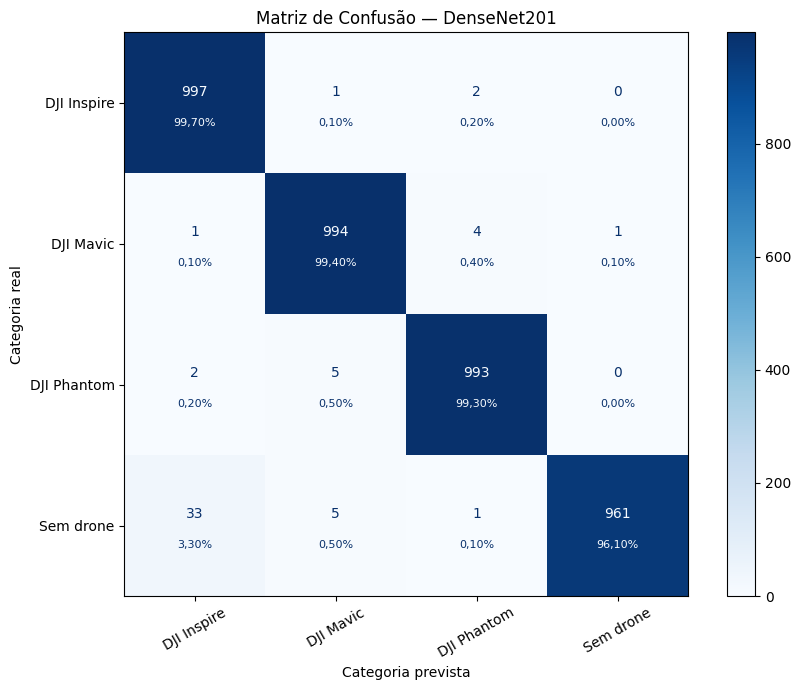

In [ ]:
import numpy as np
from decimal import Decimal, ROUND_HALF_UP

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


def acrescentar_percentuais_cm(ax, matriz):
    """Acrescenta percentuais por classe real, sem alterar as contagens."""
    matriz = np.asarray(matriz)
    totais = matriz.sum(axis=1)

    for texto in list(ax.texts):
        j, i = (
            int(round(v))
            for v in texto.get_position()
        )

        if 0 <= i < matriz.shape[0] and 0 <= j < matriz.shape[1]:
            texto.set_position((j, i - 0.08))

            if totais[i]:
                valor = (
                    Decimal(int(matriz[i, j]))
                    * 100
                    / Decimal(int(totais[i]))
                ).quantize(
                    Decimal("0.01"),
                    rounding=ROUND_HALF_UP,
                )

                percentual = (
                    str(valor) + "%"
                ).replace(".", ",")
            else:
                percentual = "—"

            ax.text(
                j,
                i + 0.14,
                percentual,
                ha="center",
                va="center",
                fontsize=8,
                color=texto.get_color(),
            )

    if np.any(totais == 0):
        ax.set_xlabel(
            ax.get_xlabel()
            + "\n—: classe real sem amostras"
        )


arquivo_contagens = (
    PASTA_RESULTADOS
    / "matriz_confusao_best_model_50epocas.npy"
)

if arquivo_contagens.is_file():
    matriz_sintetica = np.load(
        arquivo_contagens,
        allow_pickle=False,
    )
else:
    # Transcrição das contagens da figura do experimento publicado.
    # O pacote histórico contém a figura, mas não uma matriz
    # numérica separada.
    matriz_sintetica = np.array([
        [997, 1, 2, 0],
        [1, 994, 4, 1],
        [2, 5, 993, 0],
        [33, 5, 1, 961],
    ])


fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    matriz_sintetica,
    display_labels=[
        "DJI Inspire",
        "DJI Mavic",
        "DJI Phantom",
        "Sem drone",
    ],
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
)

ax.set_title("Matriz de Confusão — DenseNet201")
ax.set_xlabel("Categoria prevista")
ax.set_ylabel("Categoria real")

acrescentar_percentuais_cm(ax, matriz_sintetica)

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    PASTA_RESULTADOS
    / "matriz_confusao_best_model_50epocas_percentuais.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 7.3 Curvas de treinamento e validação

As curvas apresentadas a seguir mostram a evolução do desempenho do modelo ao longo das 50 épocas de treinamento.

A curva de **acurácia** permite acompanhar a porcentagem de classificações corretas nos conjuntos de treinamento e validação, enquanto a curva de **loss** representa a evolução da função de perda utilizada durante o processo de aprendizagem.

Essas curvas auxiliam na análise da convergência do modelo e na comparação entre seu desempenho nos dados de treinamento e de validação.

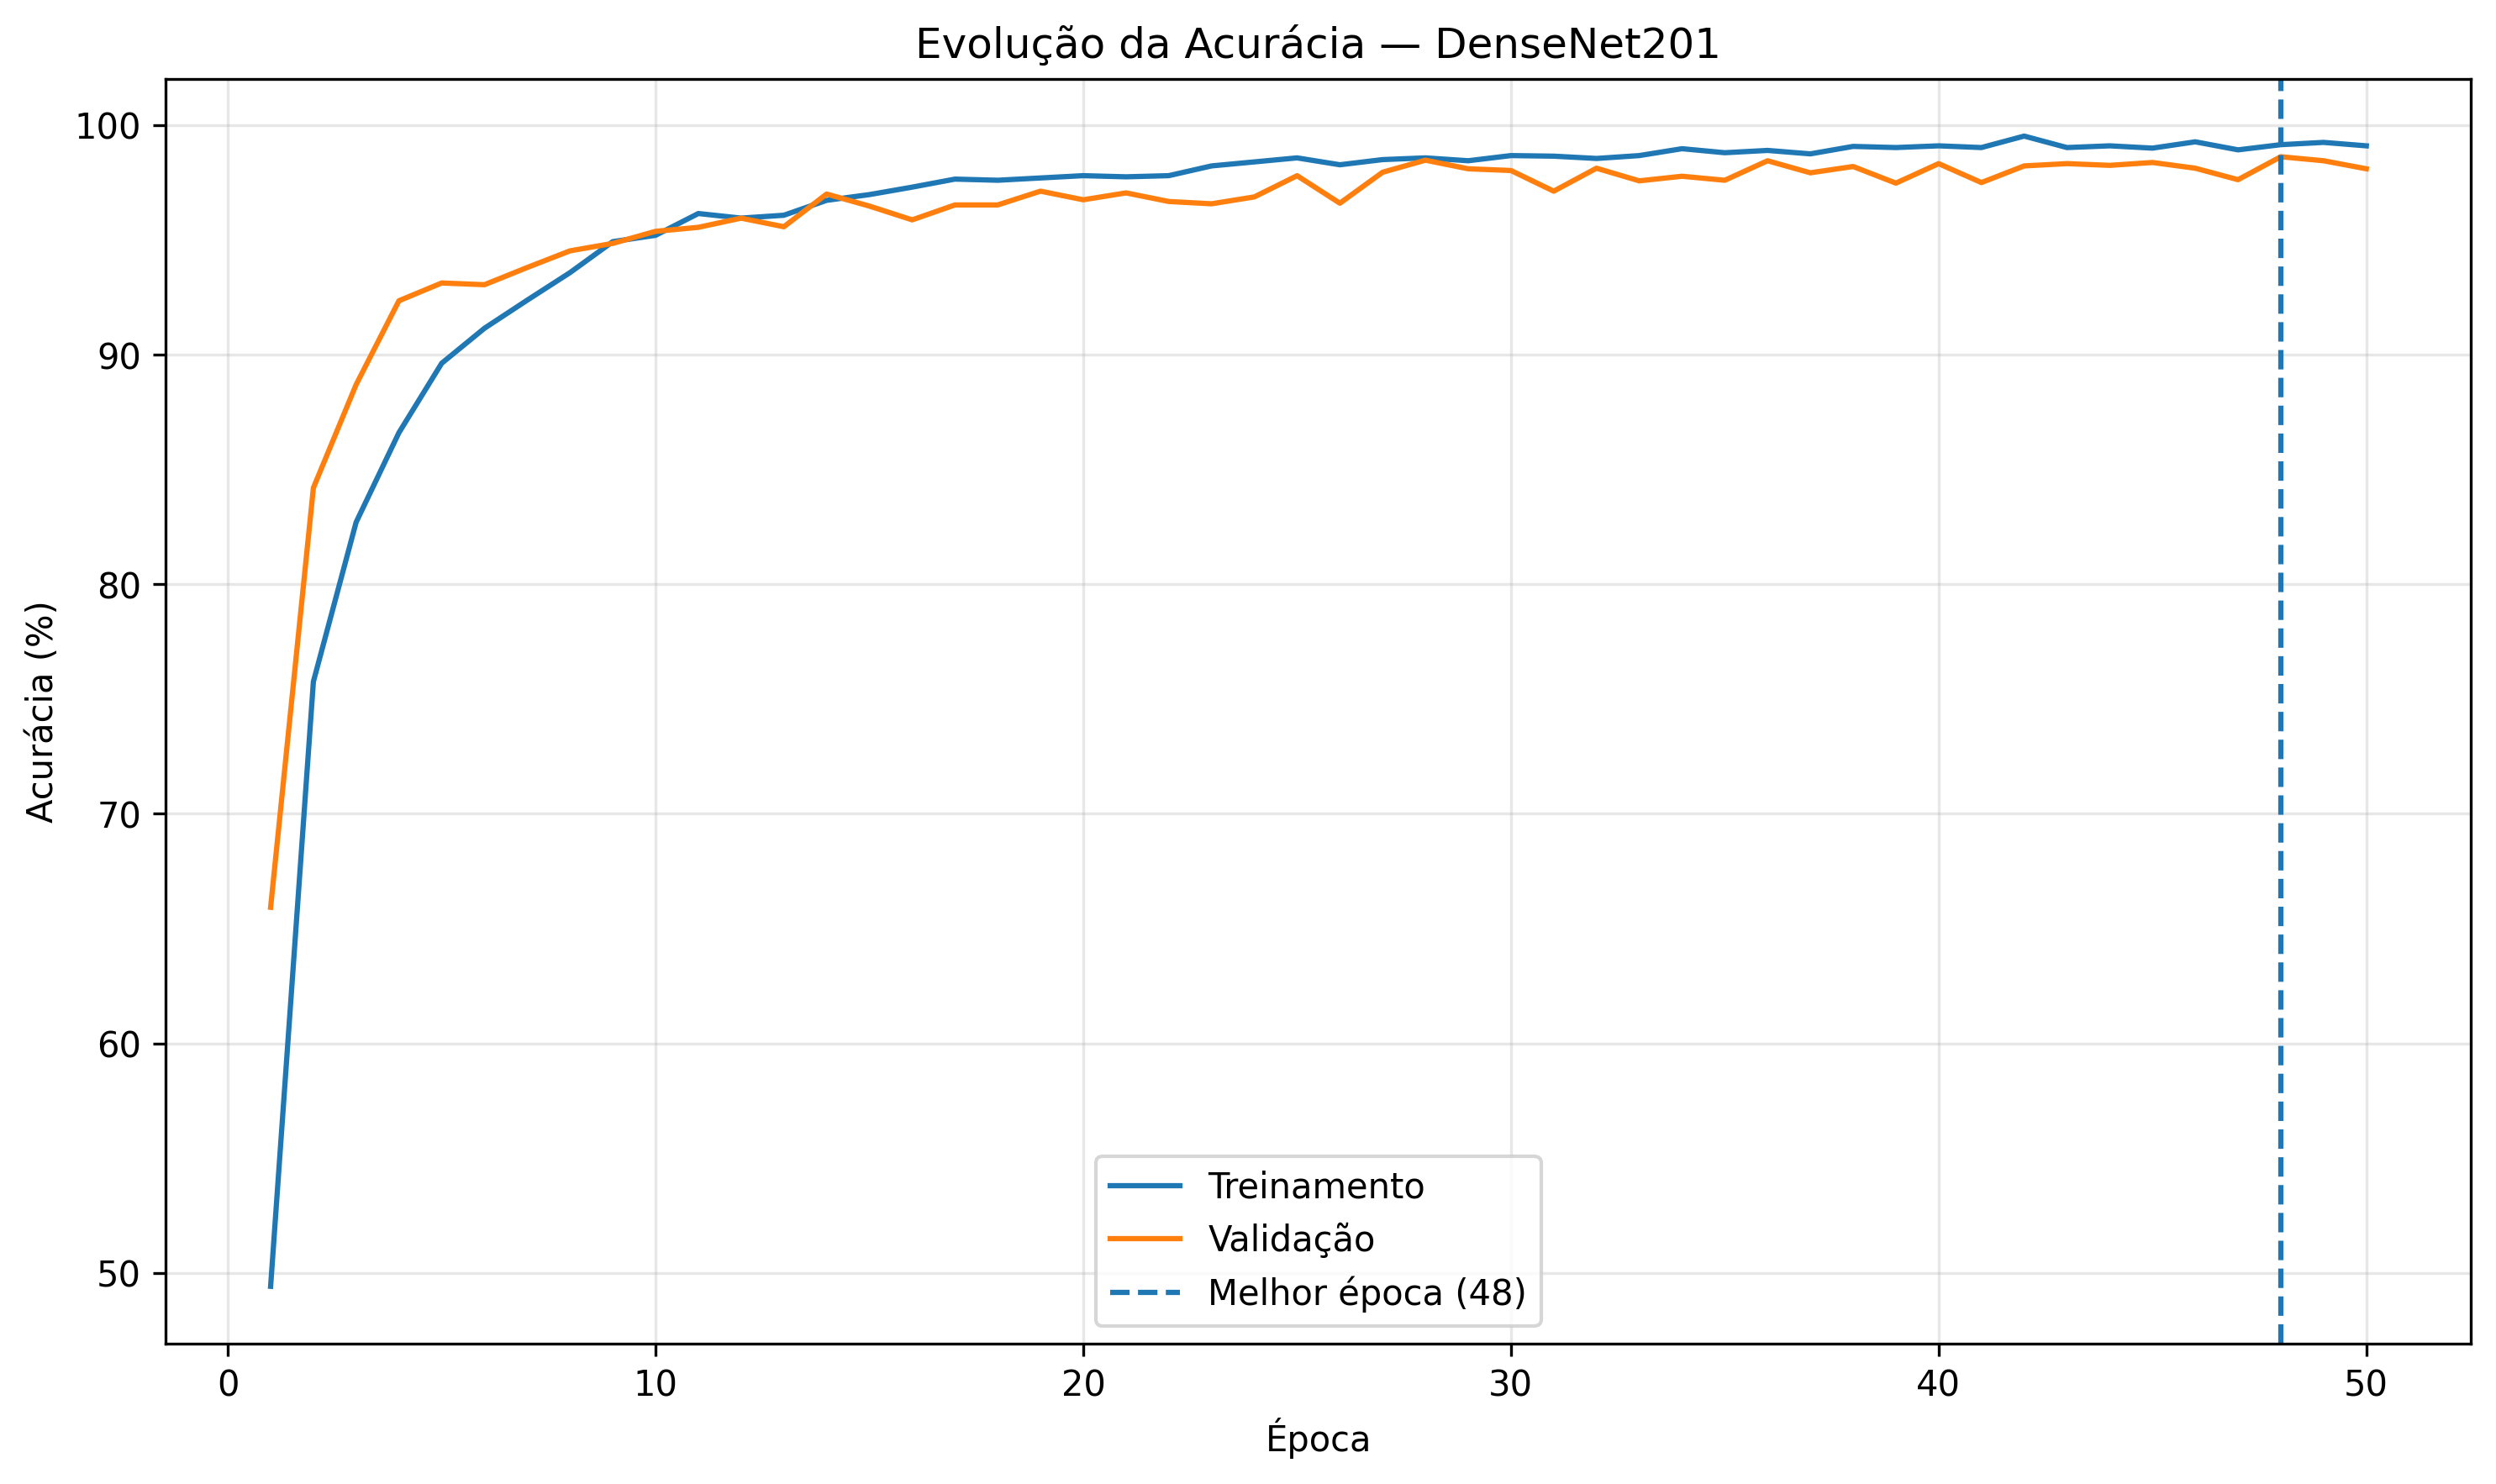

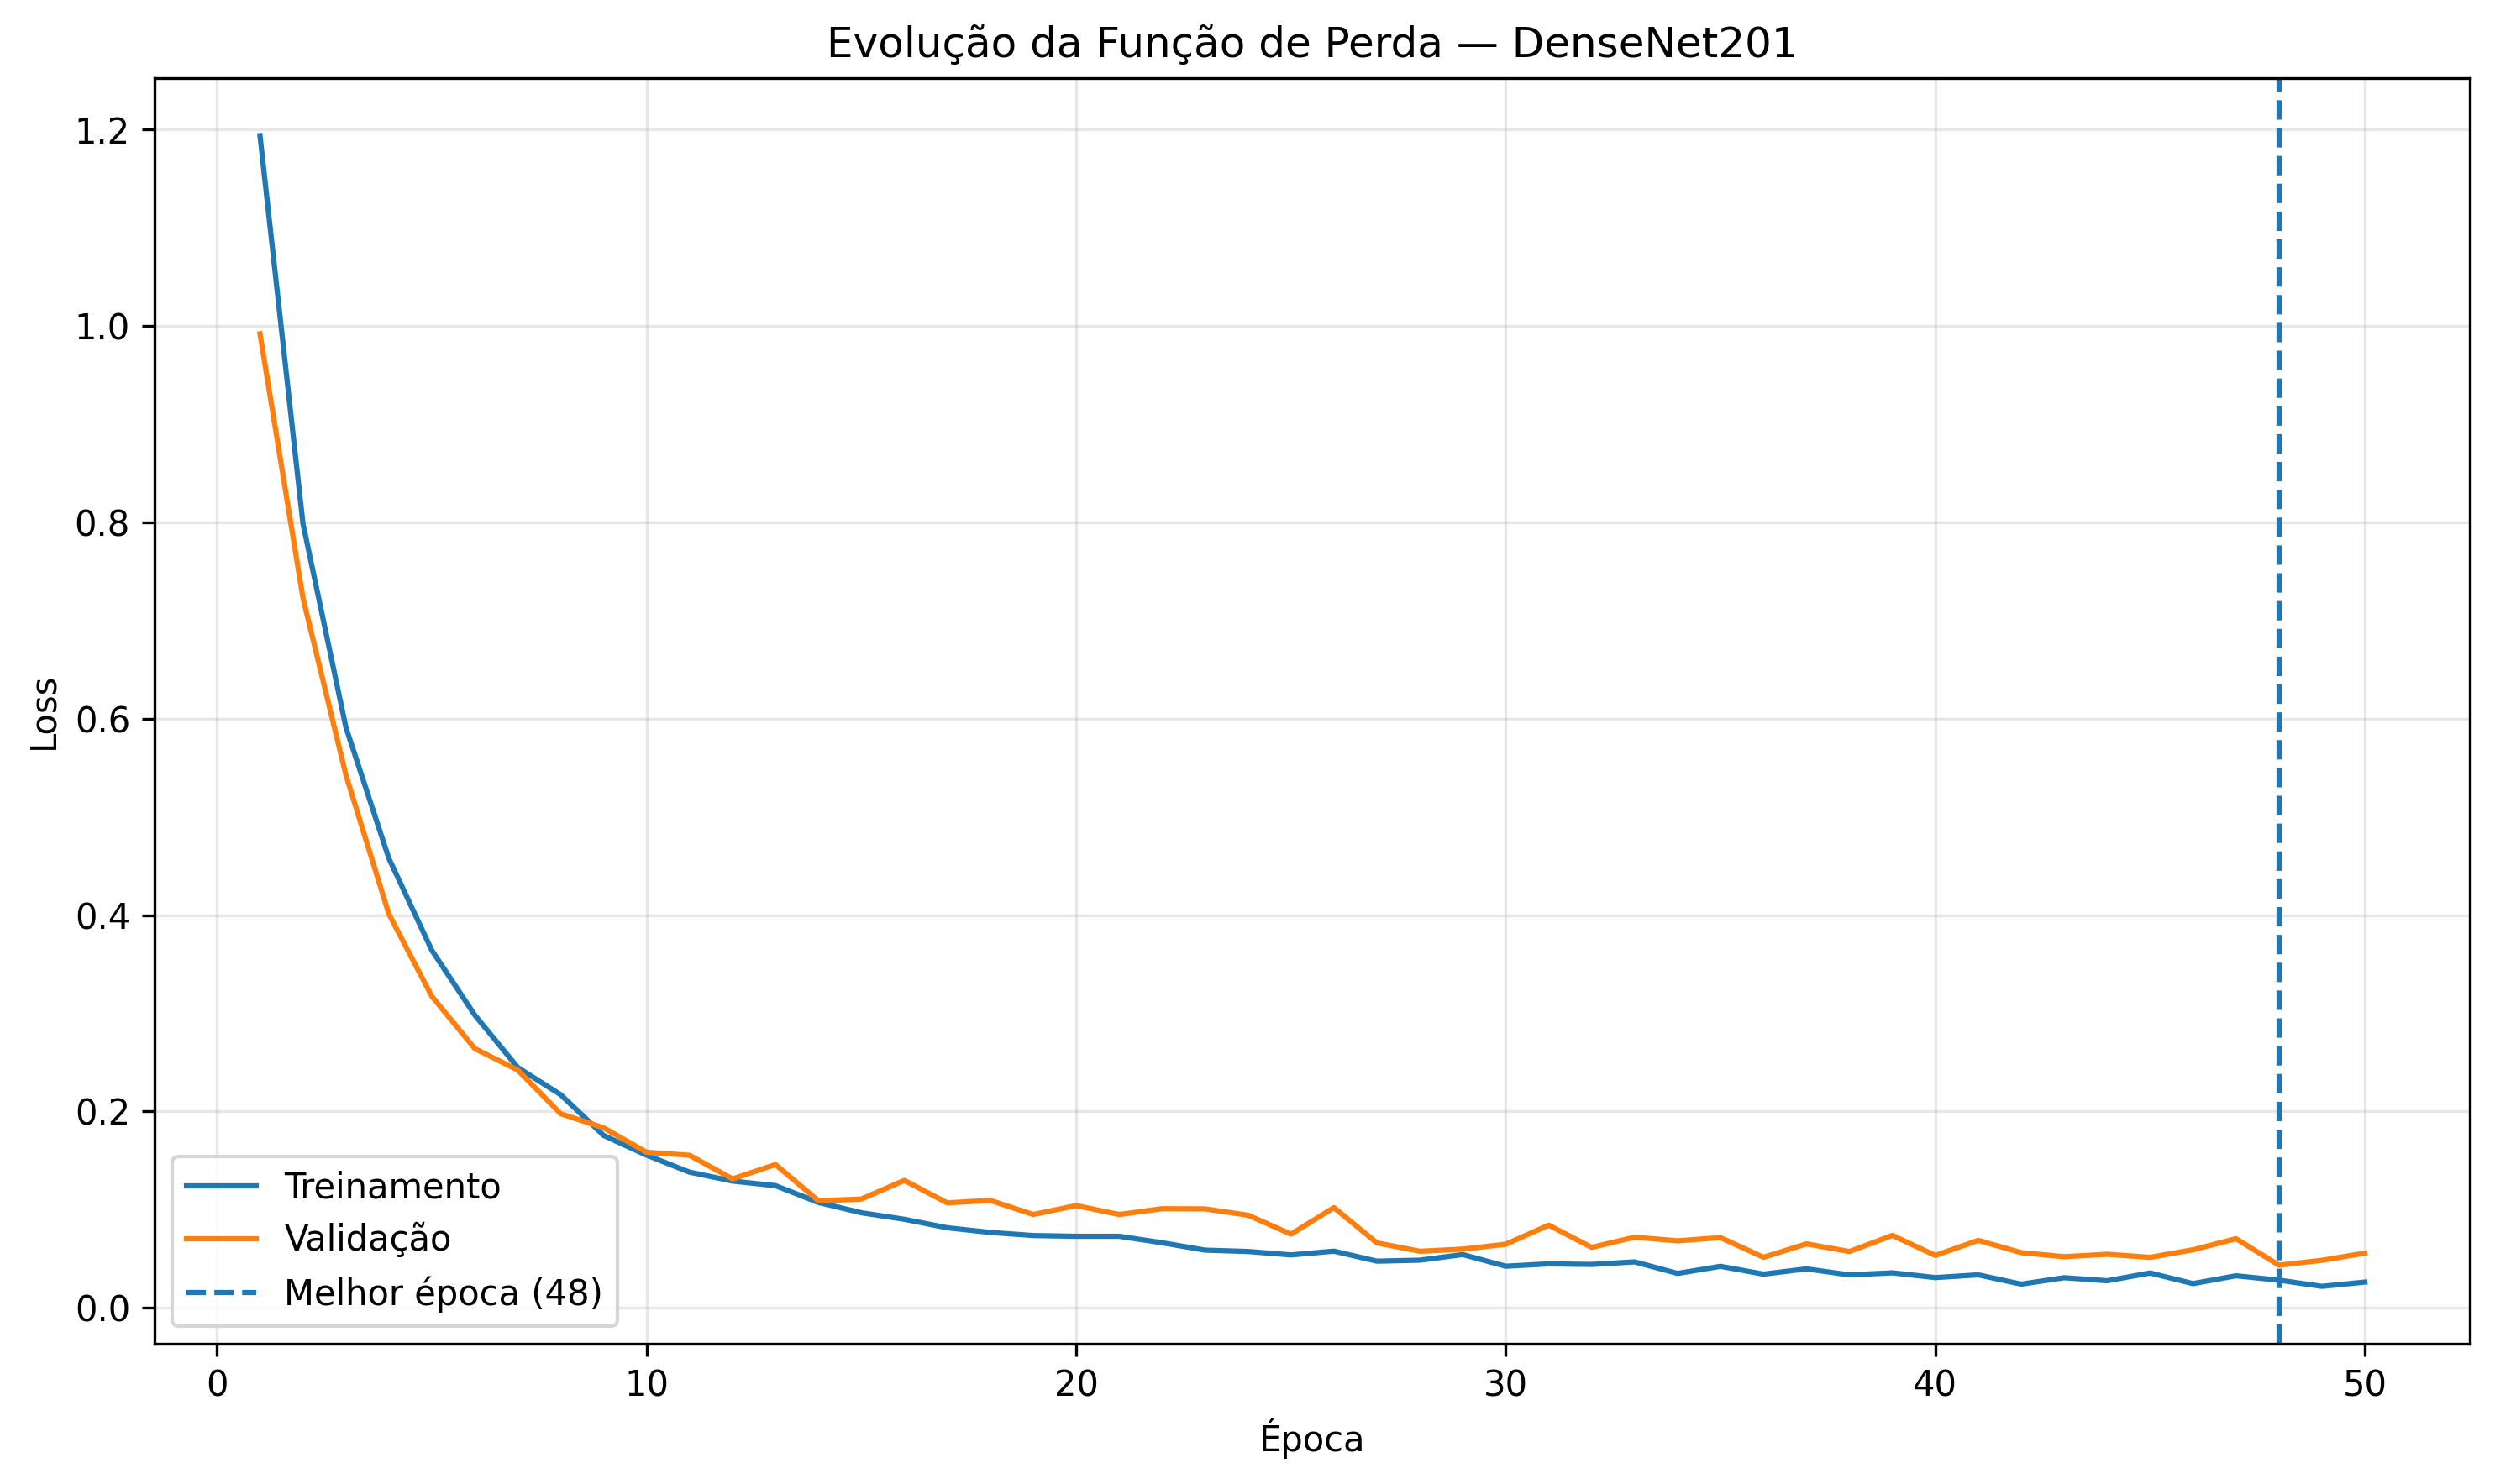

In [ ]:
from IPython.display import display, Image

display(
    Image(
        filename=str(
            PASTA_RESULTADOS /
            "curva_accuracy_50epocas.png"
        )
    )
)

display(
    Image(
        filename=str(
            PASTA_RESULTADOS /
            "curva_loss_50epocas.png"
        )
    )
)

## 8. Avaliação externa — Anti-UAV

Esta seção permite repetir a classificação das 12 sequências reais: quatro de cada modelo de drone. As anotações fornecem a localização das aeronaves; portanto, a avaliação utiliza recortes de referência e não envolve um detector.

O procedimento adotado nesta versão preserva a proporção dos recortes e completa a entrada de 224 × 224 com bordas RGB (124, 116, 104), usando interpolação bilinear e normalização ImageNet. O checkpoint permanece o mesmo.

Para consultar os resultados já obtidos, execute a configuração inicial e siga diretamente para as seções 9.1 a 9.3. Para repetir a inferência, execute as células desta seção e salve os resultados com a primeira célula da seção 9. Os arquivos da proposta inicial ficam separados e não são sobrescritos.

In [ ]:
import json

arquivos_json = sorted(ANTI_UAV_DIR.rglob("visible.json"))

print("JSON encontrados:", len(arquivos_json))
print("Exemplo:", arquivos_json[0])

with open(arquivos_json[0], "r") as f:
    dados_exemplo = json.load(f)

print("\nCampos:")
print(dados_exemplo.keys())

print("\nPrimeiros 10 valores de exist:")
print(dados_exemplo["exist"][:10])

print("\nPrimeiros 10 valores de gt_rect:")
print(dados_exemplo["gt_rect"][:10])

In [ ]:
import cv2
import json
import matplotlib.pyplot as plt
from pathlib import Path

SEQUENCIA_TESTE = Path(
    "/content/anti_uav_real/artigo24-12-sequencias/"
    "dji_inspire/20190925_130434_1_4"
)

VIDEO_PATH = SEQUENCIA_TESTE / "visible.mp4"
JSON_PATH = SEQUENCIA_TESTE / "visible.json"

# Lê as anotações
with open(JSON_PATH, "r") as f:
    annotations = json.load(f)

# Abre o vídeo
cap = cv2.VideoCapture(str(VIDEO_PATH))

ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Não foi possível ler o primeiro frame.")

# Primeira anotação
exist = annotations["exist"][0]
x, y, w, h = annotations["gt_rect"][0]

print("exist:", exist)
print("gt_rect:", [x, y, w, h])
print("Resolução do frame:", frame.shape[1], "x", frame.shape[0])

# Desenha a caixa
frame_box = frame.copy()

cv2.rectangle(
    frame_box,
    (int(x), int(y)),
    (int(x + w), int(y + h)),
    (0, 255, 0),
    4
)

# OpenCV usa BGR; matplotlib espera RGB
frame_rgb = cv2.cvtColor(frame_box, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 8))
plt.imshow(frame_rgb)
plt.title("Verificação da Ground Truth — Primeiro Frame")
plt.axis("off")
plt.show()

In [ ]:
# Recorte da região anotada
crop = frame[
    int(y):int(y + h),
    int(x):int(x + w)
]

crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(crop_rgb)
plt.title("Recorte enviado ao classificador — DJI Inspire")
plt.axis("off")
plt.show()

print("Tamanho original do recorte:", crop.shape)

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import densenet201

BEST_MODEL = BEST_MODEL_PATH

model = densenet201(weights=None)

num_features = model.classifier.in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.25),
    nn.Linear(num_features, 4)
)

model = model.to(device)

checkpoint = torch.load(
    BEST_MODEL,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Modelo carregado.")
print("Época:", checkpoint["epoch"])
print("Val Accuracy sintética:",
      f'{checkpoint["val_accuracy"] * 100:.2f}%')
print("Classes:", checkpoint["class_to_idx"])

Modelo carregado.
Época: 48
Val Accuracy sintética: 98.62%
Classes: {'dji_inspire': 0, 'dji_mavic': 1, 'dji_phantom': 2, 'no_drone': 3}


In [ ]:
from PIL import Image as PILImage, ImageOps

COR_BORDA_REAL = (124, 116, 104)

def preprocessar_real_proporcional(imagem):
    """Preserva a proporção do recorte RGB e completa a entrada com bordas."""
    if not isinstance(imagem, PILImage.Image):
        imagem = PILImage.fromarray(imagem)
    imagem = ImageOps.pad(
        imagem.convert("RGB"),
        (224, 224),
        method=PILImage.Resampling.BILINEAR,
        color=COR_BORDA_REAL,
        centering=(0.5, 0.5),
    )
    tensor = transforms.functional.to_tensor(imagem)
    return transforms.functional.normalize(tensor, imagenet_mean, imagenet_std)

real_test_transform = preprocessar_real_proporcional

print("Teste real: redimensionamento proporcional com bordas — 224 × 224.")

Teste real: redimensionamento proporcional com bordas — 224 × 224.


In [ ]:
import cv2
import json
import torch
import pandas as pd
import numpy as np
from pathlib import Path

RAIZ_REAL = Path(
    "/content/anti_uav_real/artigo24-12-sequencias"
)

# Ordem das classes da DenseNet
idx_to_class = {
    0: "dji_inspire",
    1: "dji_mavic",
    2: "dji_phantom",
    3: "no_drone"
}

resultados_frames = []
resultados_videos = []

classes_reais = [
    "dji_inspire",
    "dji_mavic",
    "dji_phantom"
]

for classe_real in classes_reais:

    pasta_classe = RAIZ_REAL / classe_real

    sequencias = sorted([
        p for p in pasta_classe.iterdir()
        if p.is_dir()
    ])

    for sequencia in sequencias:

        video_path = sequencia / "visible.mp4"
        json_path = sequencia / "visible.json"

        print(f"\nProcessando: {classe_real} / {sequencia.name}")

        # ----------------------------
        # Ler anotações
        # ----------------------------

        with open(json_path, "r") as f:
            annotations = json.load(f)

        exist_list = annotations["exist"]
        gt_rect_list = annotations["gt_rect"]

        # ----------------------------
        # Abrir vídeo
        # ----------------------------

        cap = cv2.VideoCapture(str(video_path))

        frame_idx = 0
        frames_validos = 0
        acertos_video = 0

        preds_video = {
            "dji_inspire": 0,
            "dji_mavic": 0,
            "dji_phantom": 0,
            "no_drone": 0
        }

        while True:

            ret, frame = cap.read()

            if not ret:
                break

            # Segurança contra diferenças de tamanho
            if frame_idx >= len(exist_list):
                break

            exist = exist_list[frame_idx]
            gt_rect = gt_rect_list[frame_idx]

            # Somente frames em que o alvo existe
            if exist == 1 and gt_rect is not None:

                if len(gt_rect) == 4:

                    x, y, w, h = gt_rect

                    x = int(x)
                    y = int(y)
                    w = int(w)
                    h = int(h)

                    # Garantir limites válidos
                    frame_h, frame_w = frame.shape[:2]

                    x1 = max(0, x)
                    y1 = max(0, y)
                    x2 = min(frame_w, x + w)
                    y2 = min(frame_h, y + h)

                    if x2 > x1 and y2 > y1:

                        crop = frame[y1:y2, x1:x2]

                        # OpenCV -> RGB
                        crop_rgb = cv2.cvtColor(
                            crop,
                            cv2.COLOR_BGR2RGB
                        )

                        # Preprocessing
                        input_tensor = real_test_transform(
                            crop_rgb
                        ).unsqueeze(0).to(device)

                        # Inferência
                        with torch.no_grad():
                            output = model(input_tensor)

                            pred_idx = int(
                                torch.argmax(output, dim=1).item()
                            )

                        classe_predita = idx_to_class[pred_idx]

                        correto = (
                            classe_predita == classe_real
                        )

                        frames_validos += 1

                        if correto:
                            acertos_video += 1

                        preds_video[classe_predita] += 1

                        resultados_frames.append({
                            "classe_real": classe_real,
                            "sequencia": sequencia.name,
                            "frame": frame_idx,
                            "classe_predita": classe_predita,
                            "correto": correto
                        })

            frame_idx += 1

        cap.release()

        acc_video = (
            acertos_video / frames_validos
            if frames_validos > 0
            else 0
        )

        resultados_videos.append({
            "classe_real": classe_real,
            "sequencia": sequencia.name,
            "frames_validos": frames_validos,
            "acertos": acertos_video,
            "accuracy": acc_video,
            "pred_inspire": preds_video["dji_inspire"],
            "pred_mavic": preds_video["dji_mavic"],
            "pred_phantom": preds_video["dji_phantom"],
            "pred_no_drone": preds_video["no_drone"]
        })

        print("Frames válidos:", frames_validos)
        print("Acertos:", acertos_video)
        print(f"Accuracy: {acc_video * 100:.2f}%")
        print("Predições:", preds_video)

print("\nPROCESSAMENTO CONCLUÍDO.")

## 9. Resultados reais

Os resultados apresentados nesta seção correspondem ao pré-processamento proporcional com bordas. A comparação com a proposta inicial permanece disponível na seção 10.

A célula de salvamento abaixo deve ser executada somente após repetir a avaliação da seção 8. Cada execução é salva em uma nova pasta do armazenamento temporário do Colab, separada dos resultados publicados. Use o download ao final da célula para conservar esses arquivos após o encerramento da sessão.

In [ ]:
# Execute somente após a avaliação da seção 8.
import tempfile
import shutil
from google.colab import files

if "resultados_frames" not in globals() or not resultados_frames:
    raise RuntimeError("Execute primeiro a avaliação da seção 8.")

# Cada execução recebe uma pasta própria; o Drive original não é alterado.
PASTA_RESULTADOS_REAL = Path(tempfile.mkdtemp(
    prefix="anti_uav_real_proporcional_", dir="/content"
))
df_frames = pd.DataFrame(resultados_frames)
df_videos = pd.DataFrame(resultados_videos)
df_frames_real = df_frames.copy()
df_videos_real = df_videos.copy()
CAMINHO_FRAMES_REAL = PASTA_RESULTADOS_REAL / "resultados_por_frame.csv"
CAMINHO_VIDEOS_REAL = PASTA_RESULTADOS_REAL / "resultados_por_video.csv"
df_frames_real.to_csv(CAMINHO_FRAMES_REAL, index=False)
df_videos_real.to_csv(CAMINHO_VIDEOS_REAL, index=False)
configuracao_execucao = {
    "preprocessamento": "ImageOps.pad((224,224)), BILINEAR, sem recorte central",
    "cor_borda_rgb": list(COR_BORDA_REAL),
    "normalizacao_media": imagenet_mean, "normalizacao_desvio": imagenet_std,
    "checkpoint": str(BEST_MODEL_PATH.name),
    "epoca_checkpoint": int(checkpoint["epoch"]),
    "frames": len(df_frames_real), "videos": len(df_videos_real),
}
with open(PASTA_RESULTADOS_REAL / "configuracao.json", "w", encoding="utf-8") as arquivo:
    json.dump(configuracao_execucao, arquivo, ensure_ascii=False, indent=2)
print("Nova execução salva em:", PASTA_RESULTADOS_REAL)
print("Resultados originais preservados em:", PASTA_RESULTADOS_REAL_ORIGINAL)
display(df_videos_real[["classe_real", "sequencia", "frames_validos", "acertos", "accuracy"]])
ARQUIVO_NOVA_AVALIACAO = shutil.make_archive(str(PASTA_RESULTADOS_REAL), "zip", PASTA_RESULTADOS_REAL)
print("Baixe o ZIP para preservar esta execução após o encerramento do Colab.")
files.download(ARQUIVO_NOVA_AVALIACAO)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

mapa_classes = {
    "dji_inspire": 0,
    "dji_mavic": 1,
    "dji_phantom": 2,
    "no_drone": 3
}

y_true_real = df_frames["classe_real"].map(mapa_classes).to_numpy()
y_pred_real = df_frames["classe_predita"].map(mapa_classes).to_numpy()

accuracy_real = accuracy_score(
    y_true_real,
    y_pred_real
)

precision_real, recall_real, f1_real, _ = (
    precision_recall_fscore_support(
        y_true_real,
        y_pred_real,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )
)

print("=" * 60)
print("RESULTADO GLOBAL — PROPORCIONAL (MACRO: TRÊS CLASSES REAIS)")
print("=" * 60)

print(f"Frames avaliados: {len(y_true_real)}")
print(f"Accuracy:  {accuracy_real * 100:.4f}%")
print(f"Precision: {precision_real * 100:.4f}%")
print(f"Recall:    {recall_real * 100:.4f}%")
print(f"F1-score:  {f1_real * 100:.4f}%")

print("\nRELATÓRIO POR CLASSE — sem drone não possui exemplos reais")

print(
    classification_report(
        y_true_real,
        y_pred_real,
        labels=[0, 1, 2, 3],
        target_names=[
            "DJI Inspire",
            "DJI Mavic",
            "DJI Phantom",
            "No Drone"
        ],
        digits=4,
        zero_division=0
    )
)

In [ ]:
import numpy as np
from decimal import Decimal, ROUND_HALF_UP

def acrescentar_percentuais_cm(ax, matriz):
    """Acrescenta percentuais por classe real, sem alterar as contagens."""
    matriz = np.asarray(matriz)
    totais = matriz.sum(axis=1)
    for texto in list(ax.texts):
        j, i = (int(round(v)) for v in texto.get_position())
        if 0 <= i < matriz.shape[0] and 0 <= j < matriz.shape[1]:
            texto.set_position((j, i - 0.08))
            percentual = ((str((Decimal(int(matriz[i, j])) * 100 / Decimal(int(totais[i]))).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP)) + "%").replace(".", ",")
                          if totais[i] else "—")
            ax.text(j, i + 0.14, percentual, ha="center", va="center",
                    fontsize=8, color=texto.get_color())
    if np.any(totais == 0):
        ax.set_xlabel(ax.get_xlabel() + "\n—: classe real sem amostras")

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_real = confusion_matrix(
    y_true_real,
    y_pred_real,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_real,
    display_labels=[
        "DJI Inspire",
        "DJI Mavic",
        "DJI Phantom",
        "No Drone"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    values_format="d"
)

acrescentar_percentuais_cm(ax, cm_real)

plt.title(
    "Matriz de Confusão — Teste Real Anti-UAV"
)

plt.xticks(rotation=30)
plt.tight_layout()

CAMINHO_CM_REAL = (
    PASTA_RESULTADOS_REAL /
    "matriz_confusao_anti_uav_real.png"
)

plt.savefig(
    CAMINHO_CM_REAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matriz salva em:")
print(CAMINHO_CM_REAL)

> **Reprodução e preservação dos resultados:** a configuração inicial recupera os resultados publicados dos dois pré-processamentos. A seção 8 reproduz o procedimento proporcional; o código da comparação está preservado no notebook **02_Classificacao_Drones_DenseNet201_Comparacao_Preprocessamento.ipynb**. Nenhuma célula desta avaliação grava sobre os resultados originais no Drive.

### 9.1 Resultados globais — Anti-UAV

A consulta apresenta os resultados proporcionais carregados. A comparação com o procedimento inicial está na seção 10. A acurácia considera todos os frames avaliados. Precisão, revocação (recall) e F1 macro são calculados sobre as três classes com exemplos reais: Inspire, Mavic e Phantom.

A previsão “sem drone” continua sendo contabilizada como erro quando o recorte contém uma dessas aeronaves. Como não há exemplos reais da classe “sem drone” nesta avaliação, seu reconhecimento não é medido. Os frames pertencem a 12 vídeos e não representam 12.000 observações independentes.

In [ ]:
# Resultados ativos: publicados ou da nova execução salva na seção 9.
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

df_frames_real = pd.read_csv(PASTA_RESULTADOS_REAL / "resultados_por_frame.csv")
df_videos_real = pd.read_csv(PASTA_RESULTADOS_REAL / "resultados_por_video.csv")
classes_avaliadas = ["dji_inspire", "dji_mavic", "dji_phantom"]
verdade = df_frames_real["classe_real"]
previsao = df_frames_real["classe_predita"]
p, r, f1, _ = precision_recall_fscore_support(
    verdade, previsao, labels=classes_avaliadas, average="macro", zero_division=0
)
print("RESULTADO ATIVO — PROPORCIONAL COM BORDAS")
print("Pasta:", PASTA_RESULTADOS_REAL)
print("Frames:", len(df_frames_real))
print(f"Acurácia: {accuracy_score(verdade, previsao)*100:.4f}%")
print(f"Precisão macro (3 classes): {p*100:.4f}%")
print(f"Revocação macro (3 classes): {r*100:.4f}%")
print(f"F1 macro (3 classes): {f1*100:.4f}%")
for classe in classes_avaliadas:
    grupo = df_frames_real[df_frames_real["classe_real"].eq(classe)]
    print(f"Revocação {classe}: {grupo['classe_predita'].eq(classe).mean()*100:.3f}%")



RESULTADO ATIVO — PROPORCIONAL COM BORDAS
Pasta: /content/artefatos_classificacao/resultados/anti_uav_real_proporcional_publicado
Frames: 12000
Acurácia: 90.5750%
Precisão macro (3 classes): 93.3568%
Revocação macro (3 classes): 90.5750%
F1 macro (3 classes): 91.2664%
Revocação dji_inspire: 76.100%
Revocação dji_mavic: 97.375%
Revocação dji_phantom: 98.250%


### 9.2 Resultados por vídeo — Anti-UAV

A tabela apresenta os resultados proporcionais de cada uma das 12 sequências. A análise por vídeo permite observar diferenças que ficam menos visíveis na média global.

In [ ]:
# ============================================================
# RESULTADOS POR VÍDEO — ANTI-UAV
# ============================================================

tabela_videos = df_videos_real.copy()

tabela_videos["accuracy_percent"] = (
    tabela_videos["accuracy"] * 100
).round(2)

display(
    tabela_videos[
        [
            "classe_real",
            "sequencia",
            "frames_validos",
            "acertos",
            "accuracy_percent"
        ]
    ]
)

,classe_real,sequencia,frames_validos,acertos,accuracy_percent
0,dji_inspire,20190925_130434_1_4,1000,925,92.5
1,dji_inspire,20190925_130434_1_7,1000,933,93.3
2,dji_inspire,20190925_131530_1_1,1000,318,31.8
3,dji_inspire,20190925_131530_1_4,1000,868,86.8
4,dji_mavic,20190926_141816_1_1,1000,991,99.1
5,dji_mavic,20190926_141816_1_5,1000,981,98.1
6,dji_mavic,20190926_142435_1_3,1000,981,98.1
7,dji_mavic,20190926_144550_1_2,1000,942,94.2
8,dji_phantom,20190926_130341_1_1,1000,1000,100.0
9,dji_phantom,20190926_130341_1_3,1000,1000,100.0


### 9.3 Matriz de confusão — Anti-UAV

As linhas representam as classes reais e as colunas, as previsões do classificador com pré-processamento proporcional. A linha “sem drone” permanece zerada porque a avaliação contém apenas recortes com aeronaves. As previsões dessa categoria sobre recortes de drones são erros de classificação.

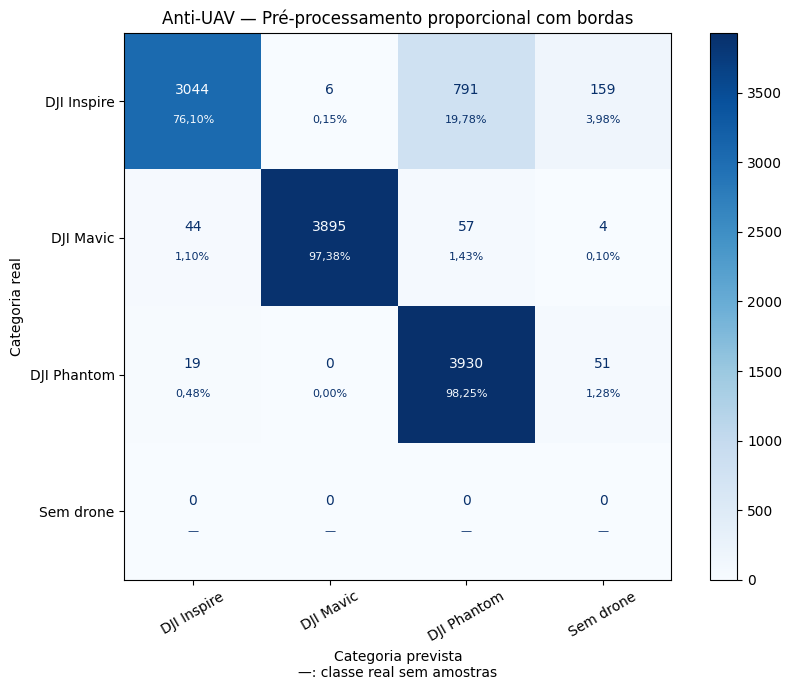

In [ ]:
import numpy as np
from decimal import Decimal, ROUND_HALF_UP

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


def acrescentar_percentuais_cm(ax, matriz):
    """Acrescenta percentuais por classe real, sem alterar as contagens."""
    matriz = np.asarray(matriz)
    totais = matriz.sum(axis=1)

    for texto in list(ax.texts):
        j, i = (
            int(round(v))
            for v in texto.get_position()
        )

        if 0 <= i < matriz.shape[0] and 0 <= j < matriz.shape[1]:
            texto.set_position((j, i - 0.08))

            if totais[i]:
                valor = (
                    Decimal(int(matriz[i, j]))
                    * 100
                    / Decimal(int(totais[i]))
                ).quantize(
                    Decimal("0.01"),
                    rounding=ROUND_HALF_UP,
                )

                percentual = (
                    str(valor) + "%"
                ).replace(".", ",")
            else:
                percentual = "—"

            ax.text(
                j,
                i + 0.14,
                percentual,
                ha="center",
                va="center",
                fontsize=8,
                color=texto.get_color(),
            )

    if np.any(totais == 0):
        ax.set_xlabel(
            ax.get_xlabel()
            + "\n—: classe real sem amostras"
        )


classes_cm = [
    "dji_inspire",
    "dji_mavic",
    "dji_phantom",
    "no_drone",
]

matriz = confusion_matrix(
    df_frames_real["classe_real"],
    df_frames_real["classe_predita"],
    labels=classes_cm,
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    matriz,
    display_labels=[
        "DJI Inspire",
        "DJI Mavic",
        "DJI Phantom",
        "Sem drone",
    ],
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
)

ax.set_title("Anti-UAV — Pré-processamento proporcional com bordas")
ax.set_xlabel("Categoria prevista")
ax.set_ylabel("Categoria real")

acrescentar_percentuais_cm(ax, matriz)

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    PASTA_RESULTADOS_REAL / "matriz_confusao_anti_uav_real.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 10. Comparação dos pré-processamentos

O reconhecimento do DJI Mavic foi baixo na avaliação inicial, que utilizava redimensionamento para 256 × 256 e recorte central de 224 × 224. Para investigar o efeito dessa preparação, os mesmos **12.000 recortes**, das **12 sequências reais**, foram classificados novamente com redimensionamento proporcional e bordas até 224 × 224. O checkpoint e as classes permaneceram os mesmos.

A acurácia passou de **59,7417% para 90,5750%**. A revocação aumentou no Mavic e no Phantom e diminuiu no Inspire, sobretudo na sequência **20190925_131530_1_1**, de **68,4% para 31,8%**. O procedimento proporcional foi adotado pelo ganho global, mantendo o registro dessa perda por classe.

**Como consultar:** execute a configuração inicial e a célula abaixo. Ela carrega as tabelas publicadas, sem repetir a inferência nem alterar os resultados. As médias macro consideram as três classes com exemplos reais; a classe “sem drone” não possui exemplos de referência nessa avaliação.

A comparação mostra o efeito conjunto das mudanças de proporção, escala, bordas e retirada do recorte central. Ela não permite atribuir todo o ganho a apenas um desses fatores. Como essas sequências orientaram a escolha do procedimento e seus frames são correlacionados, a avaliação em novos vídeos permanece necessária para verificar a generalização.

As subseções seguintes reúnem **inspeções visuais opcionais** da análise que motivou a comparação. Não são necessárias para utilizar o classificador.


MÉTRICAS GLOBAIS — MACRO SOBRE AS TRÊS CLASSES REAIS


,Método,Frames,Acurácia (%),Precisão macro — 3 classes (%),Recall macro — 3 classes (%),F1 macro — 3 classes (%)
0,original,12000,59.741667,51.874207,59.741667,50.244790
1,proporcional,12000,90.575000,93.356834,90.575000,91.266392


COMPARAÇÃO POR CLASSE


,Classe real,Frames,Acertos original,Acertos proporcional,Recall original (%),Recall proporcional (%),Diferença (p.p.),Erro → acerto,Acerto → erro
0,dji_inspire,4000,3381,3044,84.525,76.100,-8.425,184,521
1,dji_mavic,4000,7,3895,0.175,97.375,97.200,3888,0
2,dji_phantom,4000,3781,3930,94.525,98.250,3.725,150,1


COMPARAÇÃO POR VÍDEO


,Classe real,Sequência,Frames,Acertos original,Acertos proporcional,Recall original (%),Recall proporcional (%),Diferença (p.p.),Erro → acerto,Acerto → erro
0,dji_inspire,20190925_130434_1_4,1000,903,925,90.3,92.5,2.2,80,58
1,dji_inspire,20190925_130434_1_7,1000,940,933,94.0,93.3,-0.7,35,42
2,dji_inspire,20190925_131530_1_1,1000,684,318,68.4,31.8,-36.6,22,388
3,dji_inspire,20190925_131530_1_4,1000,854,868,85.4,86.8,1.4,47,33
4,dji_mavic,20190926_141816_1_1,1000,0,991,0.0,99.1,99.1,991,0
5,dji_mavic,20190926_141816_1_5,1000,4,981,0.4,98.1,97.7,977,0
6,dji_mavic,20190926_142435_1_3,1000,3,981,0.3,98.1,97.8,978,0
7,dji_mavic,20190926_144550_1_2,1000,0,942,0.0,94.2,94.2,942,0
8,dji_phantom,20190926_130341_1_1,1000,999,1000,99.9,100.0,0.1,1,0
9,dji_phantom,20190926_130341_1_3,1000,991,1000,99.1,100.0,0.9,9,0


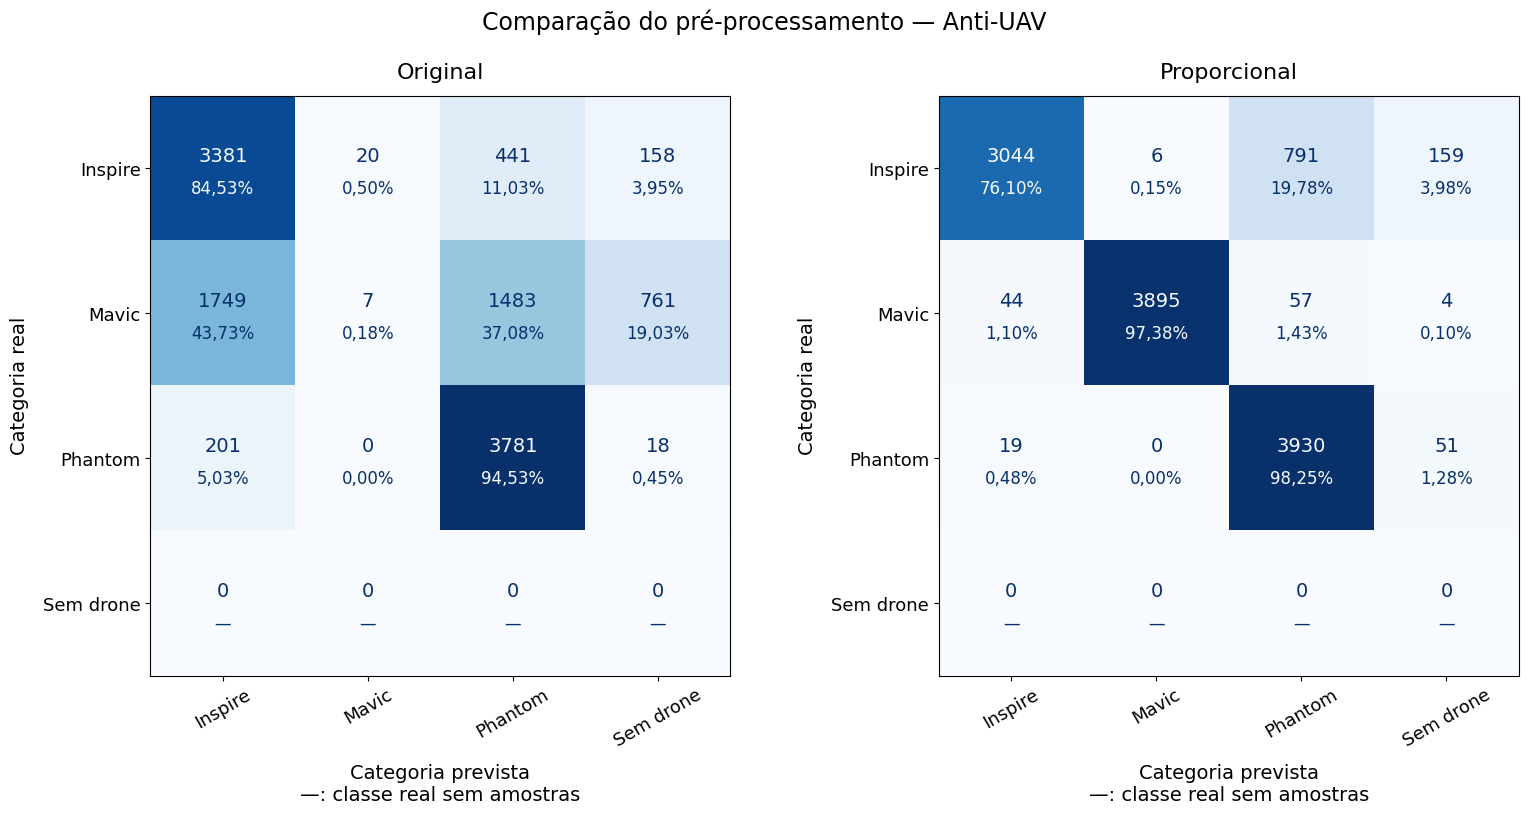

Resultados originais preservados: /content/artefatos_classificacao/resultados/anti_uav_real
Arquivos da comparação: /content/comparacao_preprocessamento_anti_uav
Pacote público para download:
https://drive.google.com/file/d/1drUHKlb6mkSbz3k96lxOM9CfCmt_NqqP/view


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decimal import Decimal, ROUND_HALF_UP
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay


# Tamanhos das fontes.
FONTE_CONTAGENS = 14
FONTE_PERCENTUAIS = 12
FONTE_CLASSES = 13
FONTE_EIXOS = 14
FONTE_TITULOS = 16
FONTE_TITULO_GERAL = 17


def acrescentar_percentuais_cm(ax, matriz):
    """Acrescenta percentuais por classe real, sem alterar as contagens."""
    matriz = np.asarray(matriz)
    totais = matriz.sum(axis=1)

    for texto in list(ax.texts):
        j, i = (
            int(round(v))
            for v in texto.get_position()
        )

        if 0 <= i < matriz.shape[0] and 0 <= j < matriz.shape[1]:
            texto.set_position((j, i - 0.08))
            texto.set_fontsize(FONTE_CONTAGENS)

            if totais[i]:
                valor = (
                    Decimal(int(matriz[i, j]))
                    * 100
                    / Decimal(int(totais[i]))
                ).quantize(
                    Decimal("0.01"),
                    rounding=ROUND_HALF_UP,
                )

                percentual = (
                    str(valor) + "%"
                ).replace(".", ",")
            else:
                percentual = "—"

            ax.text(
                j,
                i + 0.14,
                percentual,
                ha="center",
                va="center",
                fontsize=FONTE_PERCENTUAIS,
                color=texto.get_color(),
            )

    if np.any(totais == 0):
        ax.set_xlabel(
            ax.get_xlabel()
            + "\n—: classe real sem amostras",
            fontsize=FONTE_EIXOS,
            labelpad=10,
        )


# Consulta da comparação publicada; não realiza nova inferência.
if "PASTA_COMPARACAO" not in globals():
    raise RuntimeError(
        "Execute primeiro a configuração da seção 3."
    )

print("MÉTRICAS GLOBAIS — MACRO SOBRE AS TRÊS CLASSES REAIS")
display(
    pd.read_csv(
        PASTA_COMPARACAO / "metricas_globais.csv"
    )
)

print("COMPARAÇÃO POR CLASSE")
display(
    pd.read_csv(
        PASTA_COMPARACAO / "comparacao_por_classe.csv"
    )
)

print("COMPARAÇÃO POR VÍDEO")
display(
    pd.read_csv(
        PASTA_COMPARACAO / "comparacao_por_video.csv"
    )
)

classes_matriz = [
    "dji_inspire",
    "dji_mavic",
    "dji_phantom",
    "no_drone",
]

fig, eixos = plt.subplots(
    1,
    2,
    figsize=(16, 8),
)

for eixo, metodo, titulo in zip(
    eixos,
    ["original", "proporcional"],
    ["Original", "Proporcional"],
):
    tabela_matriz = pd.read_csv(
        PASTA_COMPARACAO / f"matriz_confusao_{metodo}.csv",
        index_col=0,
    )

    matriz_comparada = tabela_matriz.loc[
        classes_matriz,
        classes_matriz,
    ].to_numpy(dtype=int)

    ConfusionMatrixDisplay(
        matriz_comparada,
        display_labels=[
            "Inspire",
            "Mavic",
            "Phantom",
            "Sem drone",
        ],
    ).plot(
        ax=eixo,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    eixo.set_title(
        titulo,
        fontsize=FONTE_TITULOS,
        pad=12,
    )

    eixo.set_xlabel(
        "Categoria prevista",
        fontsize=FONTE_EIXOS,
        labelpad=10,
    )

    eixo.set_ylabel(
        "Categoria real",
        fontsize=FONTE_EIXOS,
        labelpad=10,
    )

    acrescentar_percentuais_cm(
        eixo,
        matriz_comparada,
    )

    eixo.tick_params(
        axis="both",
        labelsize=FONTE_CLASSES,
    )

    eixo.tick_params(
        axis="x",
        labelrotation=30,
    )

fig.suptitle(
    "Comparação do pré-processamento — Anti-UAV",
    fontsize=FONTE_TITULO_GERAL,
)

# Reserva espaço para o título geral e os textos ampliados.
fig.tight_layout(
    rect=(0, 0, 1, 0.95),
    w_pad=0.5,
)

fig.savefig(
    PASTA_RESULTADOS_REAL
    / "matrizes_confusao_comparadas_percentuais.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Resultados originais preservados:",
    PASTA_RESULTADOS_REAL_ORIGINAL,
)

print(
    "Arquivos da comparação:",
    PASTA_COMPARACAO,
)

print("Pacote público para download:")
print(
    "https://drive.google.com/file/d/"
    "1drUHKlb6mkSbz3k96lxOM9CfCmt_NqqP/view"
)

### 10.1 Inspeção dos recortes do Mavic — opcional

O procedimento inicial acertou **7 de 4.000 frames** de Mavic; o proporcional acertou **3.895**. O primeiro bloco abaixo permite inspecionar os recortes dos frames 0 e 500 de cada vídeo e suas previsões proporcionais. Execute a configuração inicial antes dele. São exemplos ilustrativos, que não substituem a avaliação de todos os frames.

O segundo bloco apresenta a distribuição das previsões do Mavic nos resultados proporcionais carregados. Nenhum desses blocos realiza novo treinamento.


 20190926_141816_1_1 - Frame 0
DJI Inspire: 4.08%
DJI Mavic: 89.01%
DJI Phantom: 2.64%
No Drone: 4.27%

 20190926_141816_1_1 - Frame 500
DJI Inspire: 36.43%
DJI Mavic: 54.06%
DJI Phantom: 1.46%
No Drone: 8.06%

 20190926_141816_1_5 - Frame 0
DJI Inspire: 2.57%
DJI Mavic: 72.71%
DJI Phantom: 20.94%
No Drone: 3.78%

 20190926_141816_1_5 - Frame 500
DJI Inspire: 0.55%
DJI Mavic: 66.96%
DJI Phantom: 31.44%
No Drone: 1.05%

 20190926_142435_1_3 - Frame 0
DJI Inspire: 2.25%
DJI Mavic: 82.78%
DJI Phantom: 11.21%
No Drone: 3.76%

 20190926_142435_1_3 - Frame 500
DJI Inspire: 0.31%
DJI Mavic: 97.52%
DJI Phantom: 1.46%
No Drone: 0.70%

 20190926_144550_1_2 - Frame 0
DJI Inspire: 16.70%
DJI Mavic: 64.53%
DJI Phantom: 9.48%
No Drone: 9.29%

 20190926_144550_1_2 - Frame 500
DJI Inspire: 1.55%
DJI Mavic: 86.67%
DJI Phantom: 9.39%
No Drone: 2.39%


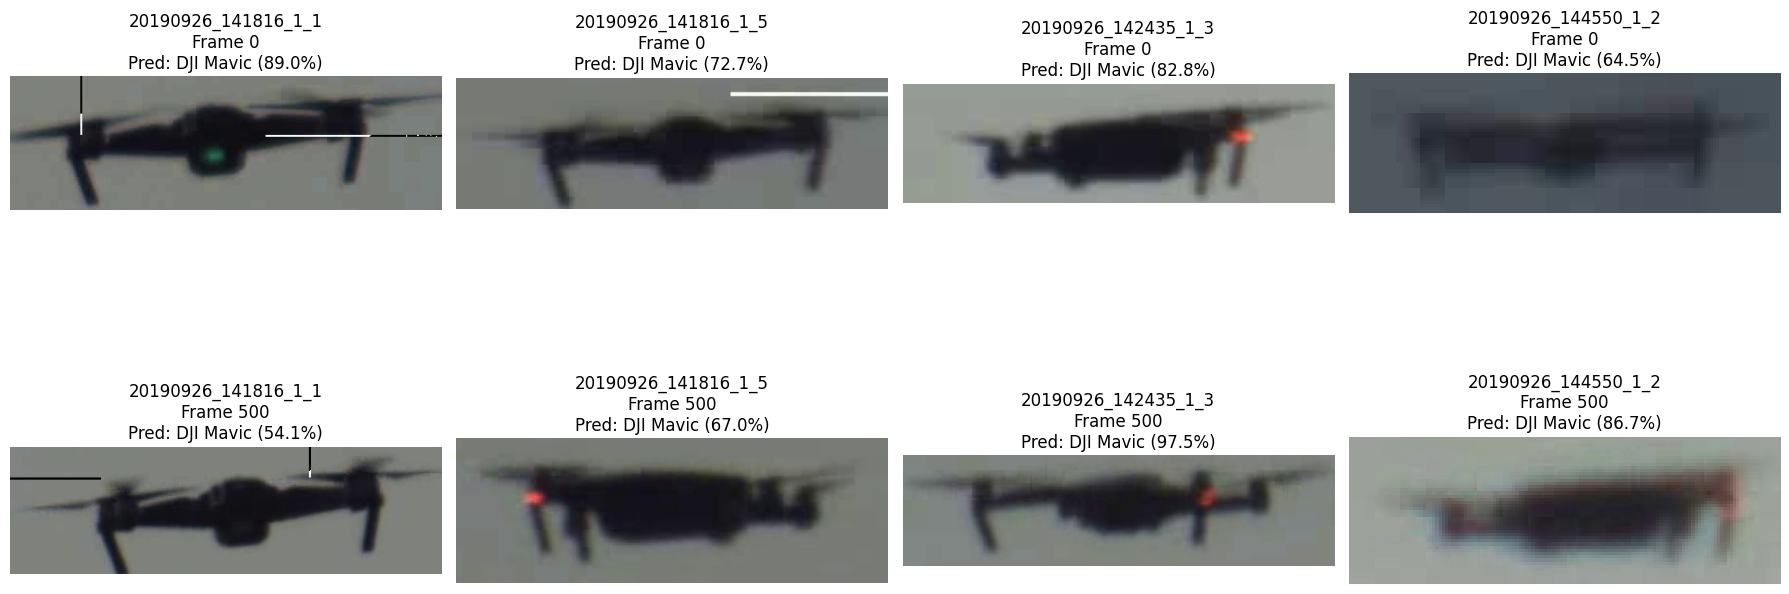

In [ ]:
import cv2
import json
import torch
import matplotlib.pyplot as plt

nomes_classes = [
    "DJI Inspire",
    "DJI Mavic",
    "DJI Phantom",
    "No Drone"
]

softmax = torch.nn.Softmax(dim=1)

sequencias_mavic = sorted(
    (RAIZ_REAL / "dji_mavic").iterdir()
)

frames_teste = [0, 500]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for col, sequencia in enumerate(sequencias_mavic):

    video_path = sequencia / "visible.mp4"
    json_path = sequencia / "visible.json"

    with open(json_path, "r") as f:
        ann = json.load(f)

    cap = cv2.VideoCapture(str(video_path))

    for row, frame_idx in enumerate(frames_teste):

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()

        if not ret:
            continue

        x, y, w, h = map(
            int,
            ann["gt_rect"][frame_idx]
        )

        crop = frame[y:y+h, x:x+w]

        crop_rgb = cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )

        input_tensor = real_test_transform(
            crop_rgb
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            output = model(input_tensor)

            probs = softmax(output)[0].cpu().numpy()

        pred_idx = int(probs.argmax())

        axes[row, col].imshow(crop_rgb)

        axes[row, col].set_title(
            f"{sequencia.name}\n"
            f"Frame {frame_idx}\n"
            f"Pred: {nomes_classes[pred_idx]} "
            f"({probs[pred_idx]*100:.1f}%)"
        )

        axes[row, col].axis("off")

        print("\n", sequencia.name, "- Frame", frame_idx)

        for nome, prob in zip(
            nomes_classes,
            probs
        ):
            print(
                f"{nome}: {prob*100:.2f}%"
            )

    cap.release()

plt.tight_layout()
plt.show()

In [ ]:
df_mavic = df_frames_real[
    df_frames_real["classe_real"]
    ==
    "dji_mavic"
]

distribuicao_mavic = (
    df_mavic["classe_predita"]
    .value_counts()
    .rename("Quantidade")
    .to_frame()
)

distribuicao_mavic["Percentual (%)"] = (
    distribuicao_mavic["Quantidade"]
    /
    len(df_mavic)
    * 100
).round(2)

display(distribuicao_mavic)

,Quantidade,Percentual (%)
classe_predita,,
dji_mavic,3895,97.38
dji_phantom,57,1.42
dji_inspire,44,1.10
no_drone,4,0.10


### 10.2 Mavic sintético e real — consulta visual opcional

São apresentados exemplos do treinamento sintético e recortes das sequências reais do Mavic. As imagens permitem observar diferenças de resolução, iluminação e aparência entre os conjuntos.

Essa comparação visual foi mantida como registro da análise inicial. O experimento com os dois pré-processamentos fornece uma avaliação direta do efeito da mudança sobre as previsões, sem isolar os efeitos da proporção, da escala do drone, das bordas e da retirada do recorte central.

Após a configuração inicial, execute a célula abaixo para visualizar a figura já salva.

COMPARAÇÃO VISUAL — DJI MAVIC
SINTÉTICO × REAL

Imagem recuperada dos resultados da execução original do experimento.



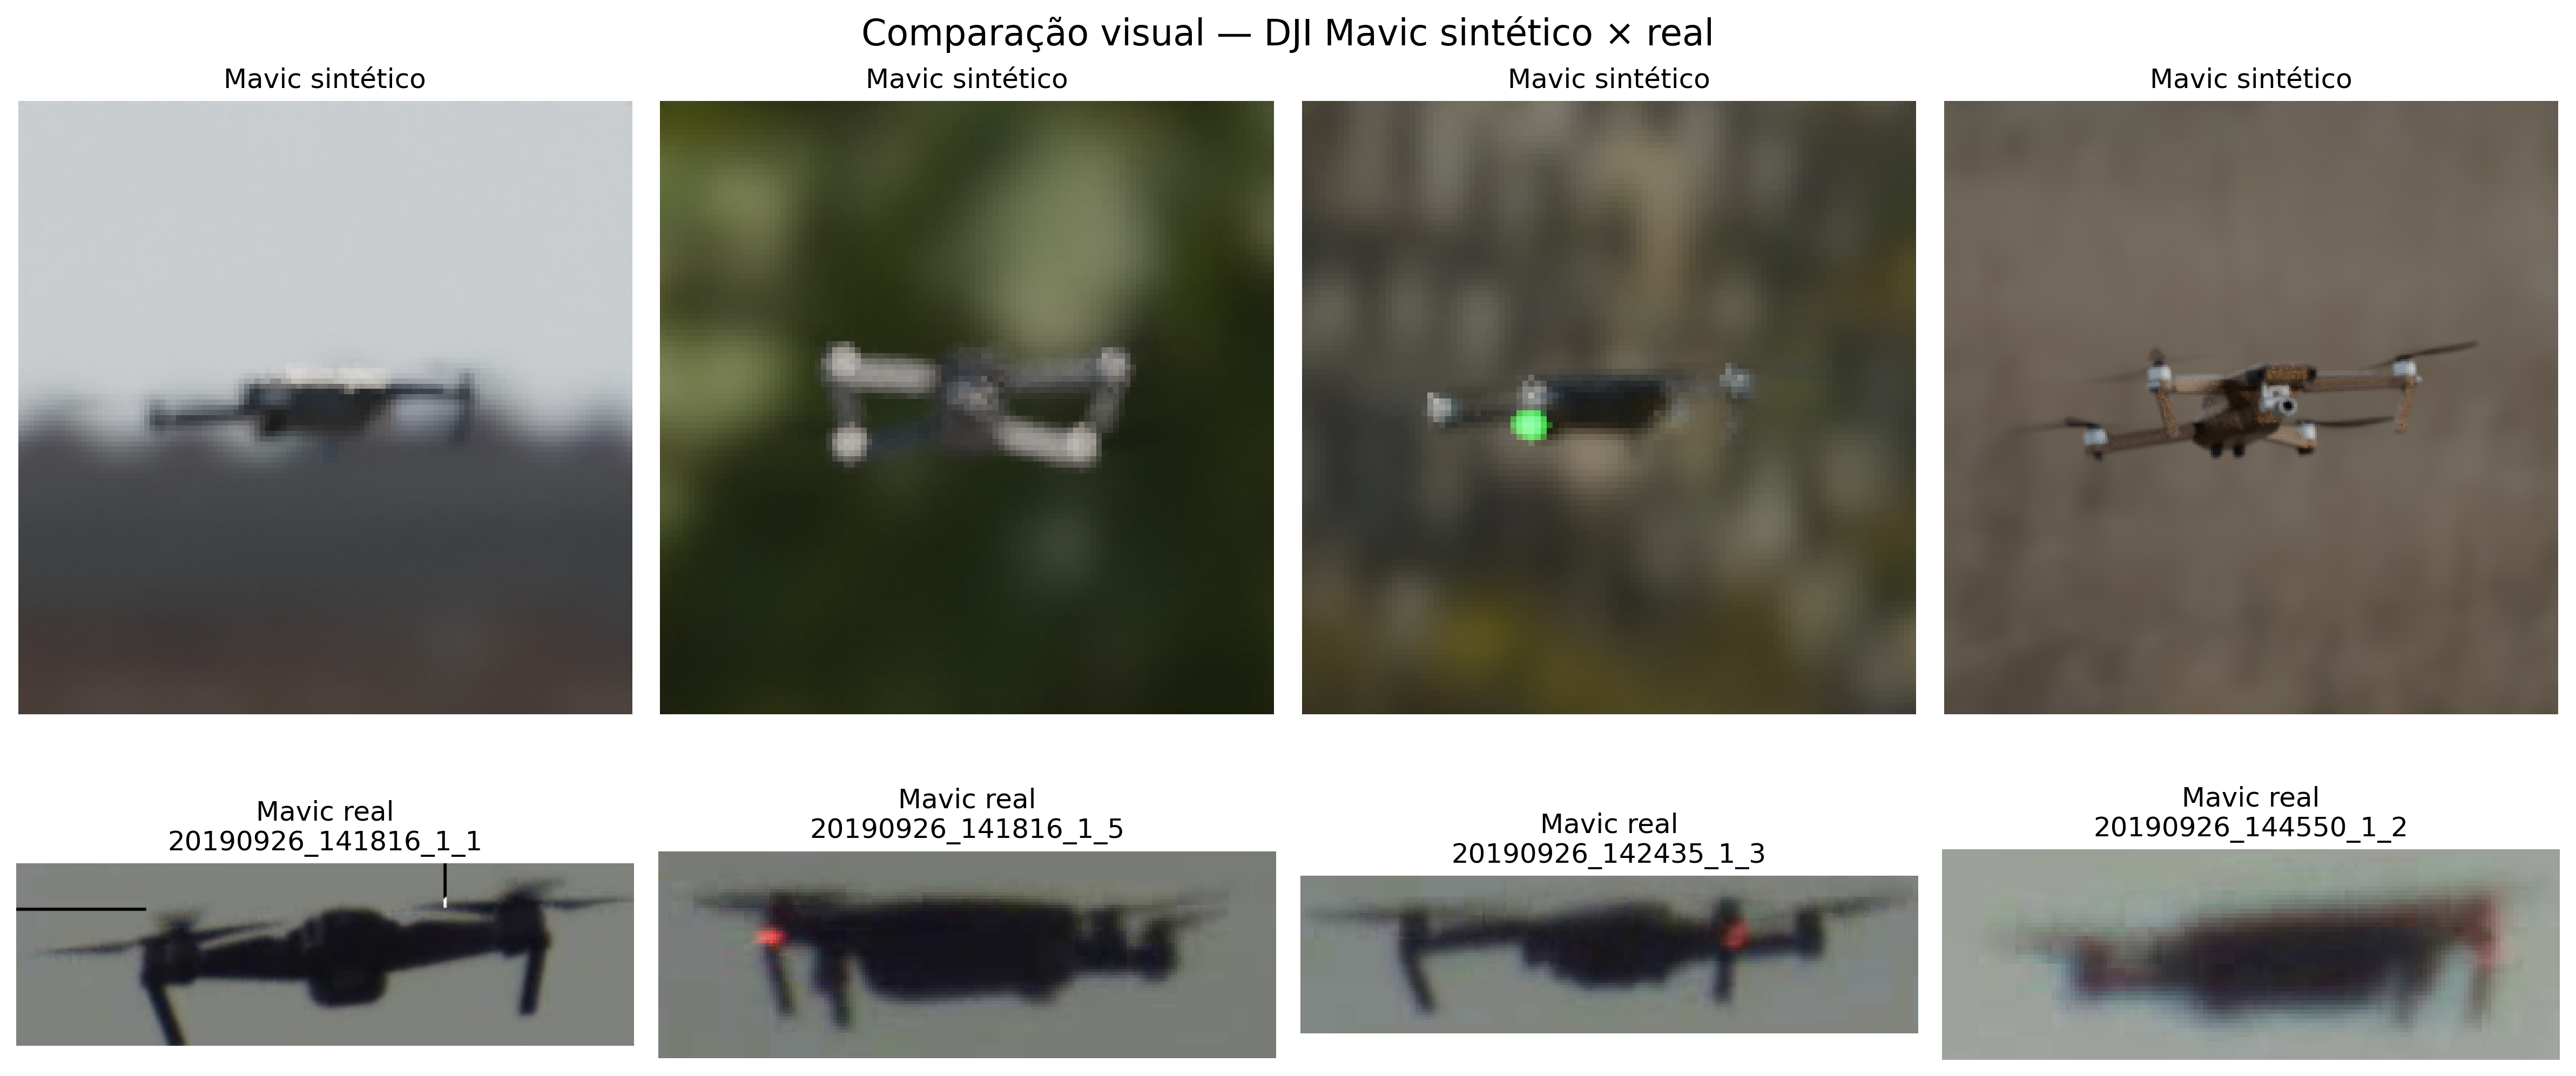

In [ ]:
# ============================================================
# COMPARAÇÃO VISUAL — MAVIC SINTÉTICO × REAL
# Resultado previamente salvo
# ============================================================

from IPython.display import display, Image

CAMINHO_COMPARACAO_MAVIC = (
    PASTA_RESULTADOS /
    "comparacao_mavic_sintetico_real.png"
)

if CAMINHO_COMPARACAO_MAVIC.is_file():

    print("=" * 70)
    print("COMPARAÇÃO VISUAL — DJI MAVIC")
    print("SINTÉTICO × REAL")
    print("=" * 70)

    print(
        "\nImagem recuperada dos resultados "
        "da execução original do experimento.\n"
    )

    display(
        Image(
            filename=str(
                CAMINHO_COMPARACAO_MAVIC
            )
        )
    )

else:

    print(
        "A imagem de comparação não foi encontrada em:\n"
        f"{CAMINHO_COMPARACAO_MAVIC}"
    )

### 10.3 Reprodução da comparação visual — Mavic sintético × real

A célula a seguir permite reproduzir a comparação visual apresentada na seção anterior diretamente a partir dos conjuntos de dados utilizados no experimento.

O procedimento seleciona exemplos da classe DJI Mavic no conjunto sintético Cranfield e extrai recortes das quatro sequências reais correspondentes no conjunto Anti-UAV, utilizando as anotações *ground truth* disponibilizadas com os vídeos.

Essa execução é opcional e não é necessária para visualizar o resultado oficial apresentado na seção 10.2. Seu objetivo é permitir a reprodução da análise a partir dos dados originais e demonstrar de forma transparente o procedimento utilizado para gerar a comparação visual.

A execução desta célula não realiza novo treinamento do classificador e não altera os resultados previamente obtidos.

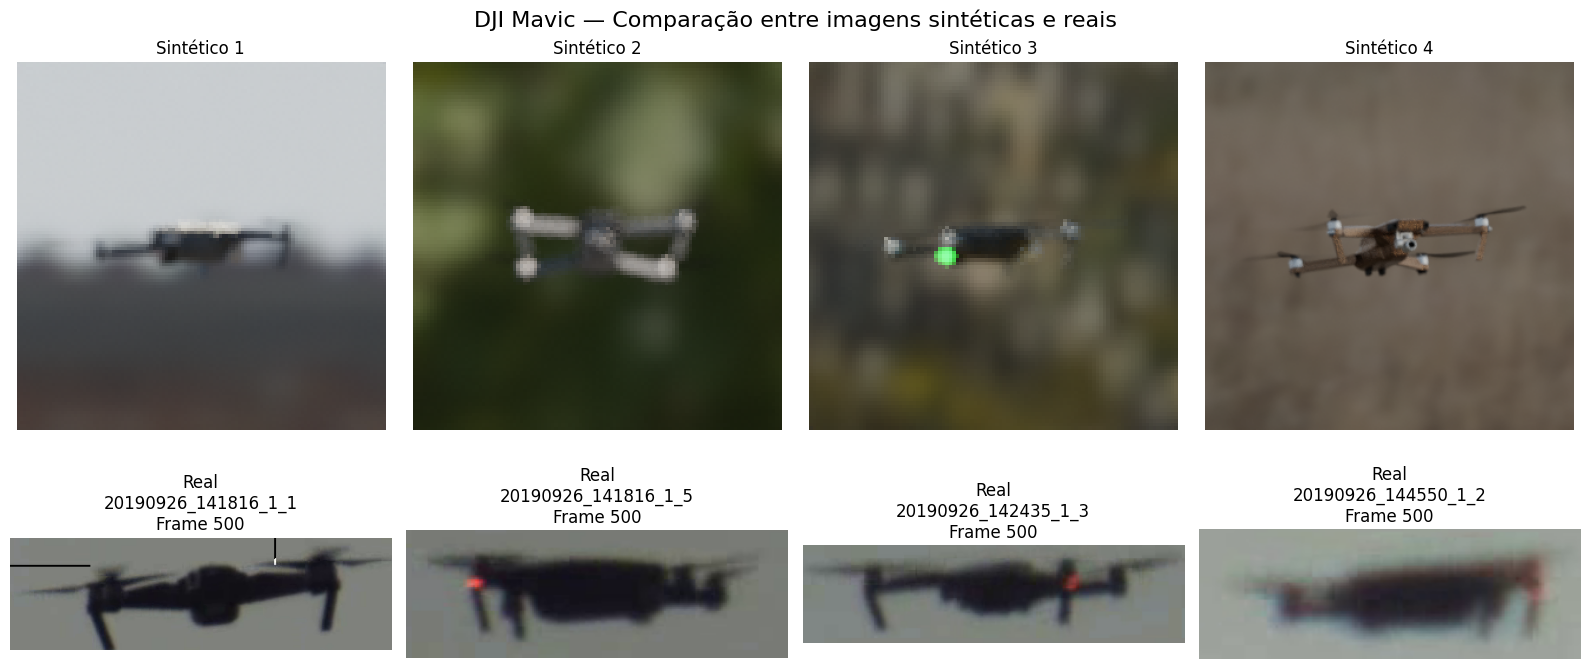


Comparação reproduzida com sucesso.
Arquivo salvo em:
/content/artefatos_classificacao/resultados/densenet201_incremental/comparacao_mavic_sintetico_real_reproduzida.png


In [ ]:
# ============================================================
# REPRODUÇÃO OPCIONAL
# Comparação visual — Mavic sintético × real
# ============================================================

import json
import cv2
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from pathlib import Path


# ------------------------------------------------------------
# 1. Selecionar exemplos sintéticos
# ------------------------------------------------------------

extensoes_imagem = {
    ".png",
    ".jpg",
    ".jpeg"
}

imagens_sinteticas = sorted([
    arquivo
    for arquivo in MAVIC_SINTETICO.iterdir()
    if arquivo.suffix.lower() in extensoes_imagem
])


if len(imagens_sinteticas) < 4:

    raise ValueError(
        "Não foram encontradas imagens sintéticas "
        "suficientes da classe DJI Mavic."
    )


# Seleção distribuída ao longo da pasta
indices = [
    0,
    len(imagens_sinteticas) // 3,
    (2 * len(imagens_sinteticas)) // 3,
    len(imagens_sinteticas) - 1
]

amostras_sinteticas = [
    imagens_sinteticas[i]
    for i in indices
]


# ------------------------------------------------------------
# 2. Localizar as quatro sequências reais de Mavic
# ------------------------------------------------------------

sequencias_mavic = sorted([
    pasta
    for pasta in MAVIC_REAL.iterdir()
    if pasta.is_dir()
])


if len(sequencias_mavic) != 4:

    raise ValueError(
        "Eram esperadas 4 sequências reais de DJI Mavic, "
        f"mas foram encontradas {len(sequencias_mavic)}."
    )


# ------------------------------------------------------------
# 3. Função para extrair um frame e recortar o drone
# ------------------------------------------------------------

def extrair_crop_real(
    pasta_sequencia,
    frame_desejado=500
):

    video_path = (
        pasta_sequencia /
        "visible.mp4"
    )

    json_path = (
        pasta_sequencia /
        "visible.json"
    )


    if not video_path.is_file():

        raise FileNotFoundError(
            f"Vídeo não encontrado: {video_path}"
        )


    if not json_path.is_file():

        raise FileNotFoundError(
            f"JSON não encontrado: {json_path}"
        )


    # Carrega as anotações
    with open(
        json_path,
        "r",
        encoding="utf-8"
    ) as f:

        anotacoes = json.load(f)


    exist = anotacoes["exist"]
    gt_rect = anotacoes["gt_rect"]


    # --------------------------------------------------------
    # Procura um frame válido próximo ao frame desejado
    # --------------------------------------------------------

    candidatos = sorted(
        range(len(exist)),
        key=lambda i: abs(i - frame_desejado)
    )


    frame_idx = None


    for i in candidatos:

        caixa = gt_rect[i]

        if (
            exist[i] == 1
            and caixa is not None
            and len(caixa) == 4
            and caixa[2] > 0
            and caixa[3] > 0
        ):

            frame_idx = i
            break


    if frame_idx is None:

        raise ValueError(
            f"Nenhum frame válido encontrado em "
            f"{pasta_sequencia.name}"
        )


    # --------------------------------------------------------
    # Lê o frame
    # --------------------------------------------------------

    cap = cv2.VideoCapture(
        str(video_path)
    )

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_idx
    )

    sucesso, frame = cap.read()

    cap.release()


    if not sucesso:

        raise RuntimeError(
            f"Não foi possível ler o frame "
            f"{frame_idx} de {video_path.name}"
        )


    # OpenCV usa BGR; matplotlib/PIL usam RGB
    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )


    # --------------------------------------------------------
    # Bounding box [x, y, largura, altura]
    # --------------------------------------------------------

    x, y, w, h = gt_rect[
        frame_idx
    ]


    x = int(x)
    y = int(y)
    w = int(w)
    h = int(h)


    altura, largura = frame.shape[:2]


    x1 = max(
        0,
        x
    )

    y1 = max(
        0,
        y
    )

    x2 = min(
        largura,
        x + w
    )

    y2 = min(
        altura,
        y + h
    )


    crop = frame[
        y1:y2,
        x1:x2
    ]


    if crop.size == 0:

        raise ValueError(
            f"Recorte vazio em "
            f"{pasta_sequencia.name}"
        )


    return (
        crop,
        frame_idx
    )


# ------------------------------------------------------------
# 4. Extrair exemplos reais
# ------------------------------------------------------------

amostras_reais = []


for sequencia in sequencias_mavic:

    crop, frame_idx = extrair_crop_real(
        sequencia,
        frame_desejado=500
    )

    amostras_reais.append(
        (
            sequencia.name,
            crop,
            frame_idx
        )
    )


# ------------------------------------------------------------
# 5. Criar comparação visual
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)


# Linha superior: sintético
for coluna, caminho in enumerate(
    amostras_sinteticas
):

    imagem = PILImage.open(
        caminho
    ).convert(
        "RGB"
    )

    axes[0, coluna].imshow(
        imagem
    )

    axes[0, coluna].set_title(
        f"Sintético {coluna + 1}"
    )

    axes[0, coluna].axis(
        "off"
    )


# Linha inferior: real
for coluna, (
    nome_sequencia,
    crop,
    frame_idx
) in enumerate(
    amostras_reais
):

    axes[1, coluna].imshow(
        crop
    )

    axes[1, coluna].set_title(
        f"Real\n{nome_sequencia}\nFrame {frame_idx}"
    )

    axes[1, coluna].axis(
        "off"
    )


fig.suptitle(
    "DJI Mavic — Comparação entre imagens sintéticas e reais",
    fontsize=16
)


plt.tight_layout()


# ------------------------------------------------------------
# 6. Salvar a nova reprodução
# ------------------------------------------------------------

CAMINHO_REPRODUCAO = (
    PASTA_RESULTADOS /
    "comparacao_mavic_sintetico_real_reproduzida.png"
)


plt.savefig(
    CAMINHO_REPRODUCAO,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "\nComparação reproduzida com sucesso."
)

print(
    "Arquivo salvo em:"
)

print(
    CAMINHO_REPRODUCAO
)

## 11. Teste com fotografia própria

Esta seção permite utilizar o classificador treinado sem repetir o treinamento. A opção **11.1** aplica o procedimento proporcional adotado no notebook. A opção **11.2** compara os dois pré-processamentos na mesma imagem.

### 11.1 Classificação com pré-processamento proporcional

1. Execute a **configuração inicial da seção 3**.
2. Na célula abaixo, troque `EXECUTAR_TESTE_EXTERNO = False` por `True`.
3. Execute a célula e selecione **uma fotografia JPG, PNG ou WebP**. Aguarde a classificação.

Utilize um recorte ao redor de um único drone, mantendo uma pequena margem e suas partes visíveis. O recorte deve vir da imagem original, **sem caixas delimitadoras ou textos desenhados**. Esta etapa não localiza objetos e não processa vídeos.

A imagem é redimensionada proporcionalmente e recebe bordas até completar **224 × 224**, sem recorte central. A saída apresenta a fotografia enviada, a entrada recebida pela rede e os escores das quatro categorias.

As categorias disponíveis são **DJI Inspire, DJI Mavic, DJI Phantom e ausência de drone**. Outras aeronaves estão fora das classes aprendidas; “ausência de drone” não significa “modelo desconhecido”. Os escores softmax não são medidas de acurácia nem garantem que a previsão esteja correta.

Esse teste individual exibe o resultado na célula. Para manter suas saídas no notebook, trabalhe em uma cópia própria e salve-a antes de encerrar a sessão. A fotografia enviada fica no armazenamento temporário do Colab.


Selecione uma única fotografia JPG, PNG ou WebP.


Saving dji-ma.jpg to /content/classificacao_externa_9qrjgrbm/dji-ma.jpg

Arquivo: dji-ma.jpg
Checkpoint: best_model_ate_50epocas.pt
Dispositivo: cpu
Categoria prevista: DJI Mavic
Escore softmax: 75.43%


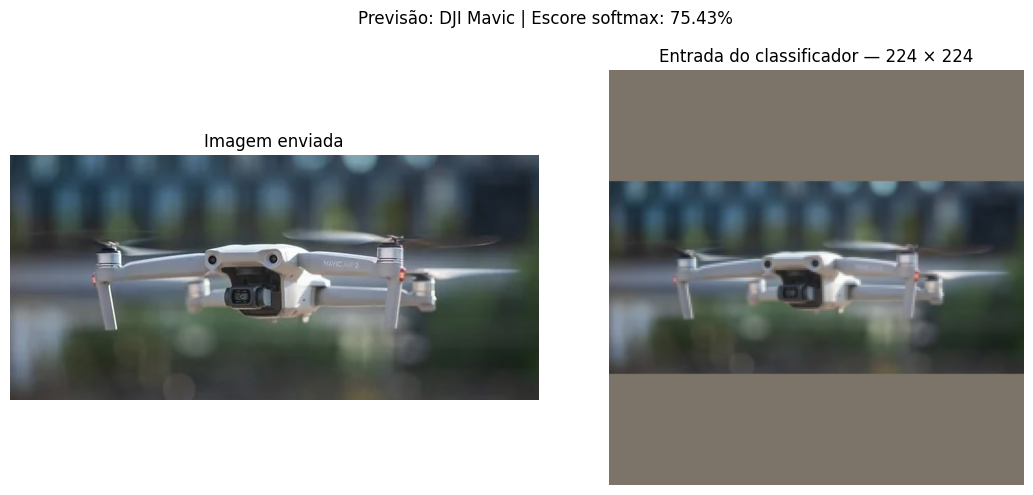

,Categoria,Escore softmax (%)
0,DJI Mavic,75.43
1,DJI Phantom,19.77
2,Ausência de drone,3.08
3,DJI Inspire,1.72



O escore não representa a acurácia do modelo nem garante que a categoria prevista esteja correta.


In [ ]:
# ============================================================
# TESTE DE CLASSIFICAÇÃO COM IMAGEM EXTERNA
# ============================================================

# Altere para True quando quiser selecionar uma fotografia.
EXECUTAR_TESTE_EXTERNO = True


def testar_imagem_externa():
    import io
    import tempfile
    from pathlib import Path

    import pandas as pd
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn

    from PIL import Image, ImageOps, UnidentifiedImageError
    from google.colab import files
    from torchvision.models import densenet201
    from IPython.display import display

    # Verificar se a restauração foi executada.
    necessarias = [
        "BEST_MODEL_PATH",
        "preprocessar_real_proporcional",
        "train_dataset",
        "imagenet_mean",
        "imagenet_std",
    ]

    ausentes = [
        nome for nome in necessarias
        if nome not in globals()
    ]

    if ausentes:
        raise RuntimeError(
            "Execute primeiro a seção de configuração e "
            "restauração do ambiente. Variáveis ausentes: "
            + ", ".join(ausentes)
        )

    caminho_modelo = Path(BEST_MODEL_PATH)

    if not caminho_modelo.is_file():
        raise FileNotFoundError(
            f"Checkpoint não encontrado: {caminho_modelo}"
        )

    # A ordem precisa corresponder à utilizada no treinamento.
    classes = [
        "dji_inspire",
        "dji_mavic",
        "dji_phantom",
        "no_drone",
    ]

    mapeamento_esperado = {
        classe: indice for indice, classe in enumerate(classes)
    }

    if train_dataset.class_to_idx != mapeamento_esperado:
        raise ValueError(
            "O mapeamento de classes difere daquele esperado "
            "para este checkpoint."
        )

    nomes = {
        "dji_inspire": "DJI Inspire",
        "dji_mavic": "DJI Mavic",
        "dji_phantom": "DJI Phantom",
        "no_drone": "Ausência de drone",
    }

    # Os arquivos enviados ficam no armazenamento desta sessão.
    pasta_upload = tempfile.mkdtemp(
        prefix="classificacao_externa_",
        dir="/content",
    )

    print("Selecione uma única fotografia JPG, PNG ou WebP.")
    enviados = files.upload(target_dir=pasta_upload)

    if not enviados:
        print("Nenhuma imagem foi selecionada.")
        return

    if len(enviados) != 1:
        print(
            "Envie apenas uma imagem por execução. "
            "Execute novamente a célula para selecionar uma foto."
        )
        return

    nome_arquivo, conteudo = next(iter(enviados.items()))

    try:
        with Image.open(io.BytesIO(conteudo)) as arquivo:
            if arquivo.format not in {"JPEG", "PNG", "WEBP"}:
                raise ValueError("Utilize uma imagem JPG, PNG ou WebP.")

            if getattr(arquivo, "n_frames", 1) > 1:
                raise ValueError(
                    "Utilize uma fotografia sem animação."
                )

            imagem = ImageOps.exif_transpose(arquivo).convert("RGB")

    except UnidentifiedImageError as erro:
        raise ValueError(
            "Não foi possível abrir o arquivo como imagem. "
            "Esta célula não processa vídeos."
        ) from erro

    # Aplicar o mesmo pré-processamento proporcional da avaliação real.
    entrada = preprocessar_real_proporcional(imagem)

    dispositivo = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # Carregar uma instância independente do melhor checkpoint.
    # Isso preserva o modelo e o otimizador das demais células.
    modelo_teste = densenet201(weights=None)
    modelo_teste.classifier = nn.Sequential(
        nn.Dropout(p=0.25),
        nn.Linear(modelo_teste.classifier.in_features, len(classes)),
    )

    # Utilizar somente o checkpoint conhecido deste projeto.
    estado = torch.load(
        caminho_modelo,
        map_location="cpu",
        weights_only=False,
    )

    modelo_teste.load_state_dict(estado["model_state_dict"])
    modelo_teste.to(dispositivo)
    modelo_teste.eval()

    with torch.inference_mode():
        saida = modelo_teste(
            entrada.unsqueeze(0).to(dispositivo)
        )
        escores = torch.softmax(saida, dim=1)[0].cpu()

    indice = int(escores.argmax().item())
    classe_prevista = nomes[classes[indice]]
    escore_previsto = float(escores[indice].item()) * 100

    print(f"\nArquivo: {Path(nome_arquivo).name}")
    print(f"Checkpoint: {caminho_modelo.name}")
    print(f"Dispositivo: {dispositivo}")
    print(f"Categoria prevista: {classe_prevista}")
    print(f"Escore softmax: {escore_previsto:.2f}%")

    # Desfazer apenas a normalização para visualizar o tensor
    # recebido pelo modelo, mantendo o redimensionamento proporcional e as bordas.
    media = torch.tensor(imagenet_mean).view(3, 1, 1)
    desvio = torch.tensor(imagenet_std).view(3, 1, 1)

    entrada_visual = (
        entrada.cpu() * desvio + media
    ).clamp(0, 1)

    fig, eixos = plt.subplots(1, 2, figsize=(11, 5))

    eixos[0].imshow(imagem)
    eixos[0].set_title("Imagem enviada")

    eixos[1].imshow(entrada_visual.permute(1, 2, 0).numpy())
    eixos[1].set_title("Entrada do classificador — 224 × 224")

    for eixo in eixos:
        eixo.axis("off")

    fig.suptitle(
        f"Previsão: {classe_prevista} | "
        f"Escore softmax: {escore_previsto:.2f}%"
    )

    plt.tight_layout()
    plt.show()

    tabela = pd.DataFrame({
        "Categoria": [nomes[classe] for classe in classes],
        "Escore softmax (%)": escores.numpy() * 100,
    }).sort_values(
        "Escore softmax (%)",
        ascending=False,
    ).reset_index(drop=True)

    display(
        tabela.style.format({"Escore softmax (%)": "{:.2f}"})
    )

    print(
        "\nO escore não representa a acurácia do modelo nem "
        "garante que a categoria prevista esteja correta."
    )


if EXECUTAR_TESTE_EXTERNO:
    testar_imagem_externa()
else:
    print(
        "Teste externo desativado. Para selecionar uma fotografia, "
        "altere EXECUTAR_TESTE_EXTERNO para True e execute esta célula."
    )

### 11.2 Comparação na mesma fotografia — opcional

Esta opção envia a mesma imagem aos dois pré-processamentos: **original**, com redimensionamento para 256 × 256 e recorte central de 224 × 224, e **proporcional**, com bordas até 224 × 224. O modelo e seus pesos são iguais nas duas previsões.

Após executar a configuração inicial, troque `EXECUTAR_COMPARACAO = False` por `True`, execute a célula abaixo e envie uma única fotografia, seguindo as orientações de recorte da seção 11.1. Não é necessário executar 11.1 antes desta comparação.

Serão exibidas as duas entradas e seus escores. A mudança de previsão em uma fotografia é uma observação exploratória; ela não mede o desempenho do modelo em um conjunto de dados. Para consultar os resultados quantitativos nas 12 sequências, utilize a seção 10. Esta célula não treina a rede nem substitui os resultados publicados.


In [ ]:
# ============================================================
# COMPARAÇÃO DO PRÉ-PROCESSAMENTO NA CLASSIFICAÇÃO
#
# A: processamento original da validação.
# B: redimensionamento proporcional com bordas (letterbox).
#
# Não modifica o modelo nem as transformações das outras células.
# ============================================================

EXECUTAR_COMPARACAO = False


def comparar_preprocessamentos():
    import io
    import tempfile
    from pathlib import Path

    import pandas as pd
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn

    from PIL import Image, ImageOps, UnidentifiedImageError
    from google.colab import files
    from torchvision import transforms
    from torchvision.models import densenet201
    from IPython.display import display

    # 1. Verificar o ambiente.
    necessarias = [
        "BEST_MODEL_PATH",
        "val_transform",
        "train_dataset",
        "imagenet_mean",
        "imagenet_std",
    ]

    ausentes = [
        nome for nome in necessarias
        if nome not in globals()
    ]

    if ausentes:
        raise RuntimeError(
            "Execute primeiro a configuração e restauração "
            "do ambiente. Variáveis ausentes: "
            + ", ".join(ausentes)
        )

    caminho_modelo = Path(BEST_MODEL_PATH)

    if not caminho_modelo.is_file():
        raise FileNotFoundError(
            f"Checkpoint não encontrado: {caminho_modelo}"
        )

    classes = [
        "dji_inspire",
        "dji_mavic",
        "dji_phantom",
        "no_drone",
    ]

    nomes = [
        "DJI Inspire",
        "DJI Mavic",
        "DJI Phantom",
        "Ausência de drone",
    ]

    esperado = {
        classe: indice for indice, classe in enumerate(classes)
    }

    if train_dataset.class_to_idx != esperado:
        raise ValueError(
            "Mapeamento de classes diferente do esperado."
        )

    # 2. Selecionar uma fotografia.
    pasta_upload = tempfile.mkdtemp(
        prefix="comparacao_classificacao_",
        dir="/content",
    )

    print("Selecione uma única fotografia JPG, PNG ou WebP.")
    enviados = files.upload(target_dir=pasta_upload)

    if not enviados:
        print("Nenhum arquivo selecionado.")
        return

    if len(enviados) != 1:
        print("Execute novamente e selecione apenas uma imagem.")
        return

    nome_arquivo, conteudo = next(iter(enviados.items()))

    try:
        with Image.open(io.BytesIO(conteudo)) as arquivo:
            if arquivo.format not in {"JPEG", "PNG", "WEBP"}:
                raise ValueError("Utilize uma imagem JPG, PNG ou WebP.")

            if getattr(arquivo, "n_frames", 1) > 1:
                raise ValueError("Utilize uma fotografia sem animação.")

            imagem = ImageOps.exif_transpose(arquivo).convert("RGB")

    except UnidentifiedImageError as erro:
        raise ValueError(
            "Não foi possível abrir o arquivo como fotografia."
        ) from erro

    # 3. Preparar as duas entradas.
    # A: utilizar exatamente a transformação original da validação.
    entrada_atual = val_transform(imagem)

    # B: preservar as proporções e completar com bordas.
    # A cor corresponde aproximadamente à média usada na
    # normalização, ficando próxima de zero após normalizar.
    cor_borda = tuple(
        round(valor * 255) for valor in imagenet_mean
    )

    imagem_proporcional = ImageOps.pad(
        imagem,
        size=(224, 224),
        method=Image.Resampling.BILINEAR,
        color=cor_borda,
        centering=(0.5, 0.5),
    )

    normalizar = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=imagenet_mean,
            std=imagenet_std,
        ),
    ])

    entrada_proporcional = normalizar(imagem_proporcional)

    entradas = [entrada_atual, entrada_proporcional]
    metodos = ["Atual", "Proporcional com bordas"]

    if any(tuple(x.shape) != (3, 224, 224) for x in entradas):
        raise ValueError(
            "As duas entradas devem possuir dimensões 3 × 224 × 224."
        )

    # 4. Carregar o checkpoint em um modelo independente.
    dispositivo = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    modelo_comparacao = densenet201(weights=None)
    modelo_comparacao.classifier = nn.Sequential(
        nn.Dropout(p=0.25),
        nn.Linear(
            modelo_comparacao.classifier.in_features,
            len(classes),
        ),
    )

    # Utilizar somente o checkpoint conhecido deste projeto.
    estado = torch.load(
        caminho_modelo,
        map_location="cpu",
        weights_only=False,
    )

    modelo_comparacao.load_state_dict(estado["model_state_dict"])
    modelo_comparacao.to(dispositivo)
    modelo_comparacao.eval()

    # 5. Classificar as duas entradas com os mesmos pesos.
    lote = torch.stack(entradas).to(dispositivo)

    with torch.inference_mode():
        saidas = modelo_comparacao(lote)
        escores = torch.softmax(saidas, dim=1).cpu()

    previsoes = escores.argmax(dim=1).tolist()

    print(f"\nArquivo: {Path(nome_arquivo).name}")
    print(f"Dimensões originais: {imagem.width} × {imagem.height}")
    print(f"Checkpoint: {caminho_modelo.name}")
    print(f"Dispositivo: {dispositivo}")
    print(f"Cor das bordas (RGB): {cor_borda}")

    # 6. Mostrar a imagem original e as duas entradas reais.
    media = torch.tensor(imagenet_mean).view(3, 1, 1)
    desvio = torch.tensor(imagenet_std).view(3, 1, 1)

    fig, eixos = plt.subplots(1, 3, figsize=(15, 5))

    eixos[0].imshow(imagem)
    eixos[0].set_title("Imagem original")

    for i, entrada in enumerate(entradas):
        visual = (
            entrada.cpu() * desvio + media
        ).clamp(0, 1)

        indice = previsoes[i]
        escore = escores[i, indice].item() * 100

        eixos[i + 1].imshow(
            visual.permute(1, 2, 0).numpy()
        )
        eixos[i + 1].set_title(
            f"{metodos[i]} — 224 × 224\n"
            f"{nomes[indice]} | {escore:.2f}%"
        )

    for eixo in eixos:
        eixo.axis("off")

    plt.tight_layout()
    plt.show()

    # 7. Comparar os escores de todas as categorias.
    tabela = pd.DataFrame({
        "Categoria": nomes,
        "Original (%)": escores[0].numpy() * 100,
        "Proporcional com bordas (%)": escores[1].numpy() * 100,
    })

    display(
        tabela.style.format({
            "Original (%)": "{:.2f}",
            "Proporcional com bordas (%)": "{:.2f}",
        })
    )

    if previsoes[0] != previsoes[1]:
        print("\nA categoria prevista mudou entre os processamentos.")
    else:
        print("\nA categoria prevista permaneceu a mesma.")

    print(
        "Esta comparação é exploratória. Os percentuais são "
        "escores softmax, não medidas de acurácia."
    )


if EXECUTAR_COMPARACAO:
    comparar_preprocessamentos()
else:
    print(
        "Comparação desativada. Altere EXECUTAR_COMPARACAO "
        "para True e execute novamente para selecionar uma imagem."
    )

Comparação desativada. Altere EXECUTAR_COMPARACAO para True e execute novamente para selecionar uma imagem.


## 12. Conclusões preliminares

A validação sintética mantém acurácia de **98,6250%**, com o melhor checkpoint na época **48**. Na comparação dos mesmos **12.000 frames reais**, a acurácia passou de **59,7417%** no procedimento inicial para **90,5750%** com o redimensionamento proporcional com bordas, ganho de **30,8333 pontos percentuais**.

A revocação do Mavic passou de **0,175%** para **97,375%**, e a do Phantom, de **94,525%** para **98,250%**. Para o Inspire, houve redução de **84,525%** para **76,100%**, concentrada sobretudo em uma sequência. O procedimento proporcional foi adotado pelo melhor resultado global neste conjunto, com registro dessa perda por classe.

A alteração foi realizada somente na inferência, sem novo treinamento. Os resultados mostram o efeito do conjunto de mudanças no pré-processamento, incluindo proporção, escala e bordas. Como essas sequências orientaram a escolha do procedimento, a comparação é exploratória; sua generalização deve ser avaliada em novos dados.